# Mutations linked to antibiotic resistance in *Mycobacterium tuberculosis*

**Computing for Bioinformatics: group project (Group C)**

Data: CRyPTIC Consortium compendium of 12,287 clinical *M. tuberculosis* isolates, each with a
whole-genome sequence and laboratory drug-susceptibility results for 13 antibiotics.

The notebook follows the eight stages of the project brief in order. Each stage ends with an
interpretation of the results produced above it.

## Stage 1: Research question and objectives

**Research question.** Which specific genetic mutations in *Mycobacterium tuberculosis* are most
strongly linked to antibiotic resistance?

*M. tuberculosis* does not pick up resistance genes from other bacteria. It becomes resistant
through mutations in its own chromosome, mostly in the gene for the drug's target or for the
enzyme that activates the drug. So if we know which mutations each isolate carries and whether it
grew in the presence of each drug, we can measure how strongly each mutation goes with resistance.

**Objectives**

1. Build a clean dataset that links the mutations each isolate carries in 43 known and candidate
   resistance genes to its laboratory result (resistant or susceptible) for 13 drugs.
2. Measure and rank the association between every mutation and resistance to every drug (odds
   ratio, Fisher's exact test with false discovery rate correction, positive predictive value),
   and check that the ranking holds within each lineage of the bacterium.
3. Interpret the top-ranked mutations biologically: where they fall in the protein, how much they
   raise the minimum inhibitory concentration (MIC), which drugs share them (network analysis),
   and whether they agree with the published literature.
4. Predict resistance from mutations with machine learning and compare the models against two
   baselines: always predicting the majority class, and a rule that uses only the single strongest
   mutation.

**Hypothesis.** Resistance to each drug is explained mostly by a few mutations in the gene for
the drug's target or activating enzyme (for example *rpoB* for rifampicin, *katG* for isoniazid).
These mutations will have very large odds ratios. Synonymous mutations, and mutations that only
mark a lineage, will show little or no association once lineage is taken into account.

**Null hypothesis** (tested for each mutation and drug): carrying the mutation is not associated
with resistance (odds ratio = 1).

In [1]:
# Libraries. All of them are preinstalled in Google Colab.
import subprocess
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import networkx as nx
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import display
from scipy.stats import fisher_exact
from sklearn.decomposition import PCA
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, roc_auc_score
from sklearn.model_selection import GroupKFold, StratifiedKFold
from statsmodels.stats.contingency_tables import StratifiedTable
from statsmodels.stats.multitest import multipletests
from statsmodels.stats.proportion import proportion_confint

warnings.filterwarnings("ignore", category=RuntimeWarning)
pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 180)
sns.set_theme(style="whitegrid", context="notebook")
SEED = 42

DRUGS = {
    "INH": "Isoniazid", "RIF": "Rifampicin", "RFB": "Rifabutin", "EMB": "Ethambutol",
    "ETH": "Ethionamide", "LEV": "Levofloxacin", "MXF": "Moxifloxacin", "AMI": "Amikacin",
    "KAN": "Kanamycin", "LZD": "Linezolid", "BDQ": "Bedaquiline", "CFZ": "Clofazimine",
    "DLM": "Delamanid",
}
# Epidemiological cut-off (mg/L): an MIC above this value is called resistant.
ECOFF = {"INH": 0.1, "RIF": 0.5, "RFB": 0.12, "EMB": 4, "ETH": 4, "LEV": 1, "MXF": 1,
         "AMI": 1, "KAN": 4, "LZD": 1, "BDQ": 0.25, "CFZ": 0.25, "DLM": 0.12}
# Genes with a known or proposed role in resistance to each drug (WHO mutation catalogue).
DRUG_GENES = {
    "RIF": ["rpoB", "rpoA", "rpoC"],
    "RFB": ["rpoB", "rpoA", "rpoC"],
    "INH": ["katG", "inhA", "fabG1", "ahpC", "ndh", "kasA", "mshA"],
    "ETH": ["ethA", "ethR", "inhA", "fabG1", "ndh", "mshA"],
    "EMB": ["embA", "embB", "embC", "embR", "ubiA", "aftA", "aftB"],
    "LEV": ["gyrA", "gyrB"],
    "MXF": ["gyrA", "gyrB"],
    "AMI": ["rrs", "eis", "whiB7", "tlyA"],
    "KAN": ["rrs", "eis", "whiB7", "tlyA"],
    "LZD": ["rplC", "rrl"],
    "BDQ": ["Rv0678", "atpE", "pepQ", "mmpL5", "mmpS5"],
    "CFZ": ["Rv0678", "pepQ", "mmpL5", "mmpS5"],
    "DLM": ["ddn", "fgd1", "fbiA", "fbiB", "fbiC", "Rv2983"],
}
DRUG_ORDER = list(DRUGS)

## Stage 2: Data acquisition

**Source.** The CRyPTIC Consortium (2022), *A data compendium associating the genomes of 12,289
Mycobacterium tuberculosis isolates with quantitative resistance phenotypes to 13 antibiotics*,
PLOS Biology 20(8): e3001721, doi:10.1371/journal.pbio.3001721. The data are public on the
EMBL-EBI FTP server: `http://ftp.ebi.ac.uk/pub/databases/cryptic/release_june2022/`.

CRyPTIC collected isolates from patients in 23 countries, sequenced every genome, and grew every
isolate on a 96-well plate holding a dilution series of 13 drugs to measure its MIC.

The full mutation table is 1.4 GB compressed (every mutation in every gene of every isolate).
`scripts/build_dataset.py` in this repository downloads the original tables once and keeps only
the rows this project needs. It writes the three small files below into `data/`, which are
committed to the repository so the notebook runs in a few minutes.

| File | One row per | Built from |
|---|---|---|
| `cryptic_phenotypes.csv.gz` | isolate | `reuse/CRyPTIC_reuse_table_20240917.csv` |
| `cryptic_genomes.csv.gz` | isolate | `.../cryptic-analysis-group/GENOMES.csv.gz` |
| `cryptic_candidate_gene_mutations.csv.gz` | isolate and mutation | `.../cryptic-analysis-group/MUTATIONS.csv.gz`, 43 candidate genes only |

**To run in Google Colab:** set `REPO_URL` below to the GitHub address of this repository. The
cell clones it so the data files are available. When the notebook is run from inside the
repository folder, `REPO_URL` is not needed.

In [2]:
REPO_URL = "https://github.com/EKR4T/bioinformaticsproject"   # GitHub repository that holds this project

FILES = ["cryptic_phenotypes.csv.gz", "cryptic_genomes.csv.gz",
         "cryptic_candidate_gene_mutations.csv.gz"]


def find_data():
    for base in [Path("data"), Path("tb-resistance-mutations/data"),
                 Path("bioinformaticsproject/tb-resistance-mutations/data")]:
        if all((base / f).exists() for f in FILES):
            return base
    return None


DATA = find_data()
if DATA is None and REPO_URL:
    subprocess.run(["git", "clone", "--depth", "1", REPO_URL, "bioinformaticsproject"], check=True)
    DATA = find_data()
if DATA is None:
    raise FileNotFoundError("Data files not found. Set REPO_URL above, or run "
                            "`python scripts/build_dataset.py` to rebuild them from the CRyPTIC FTP.")

pheno_raw = pd.read_csv(DATA / "cryptic_phenotypes.csv.gz", low_memory=False)
genomes_raw = pd.read_csv(DATA / "cryptic_genomes.csv.gz", dtype={"SITEID": str}, low_memory=False)
muts_raw = pd.read_csv(DATA / "cryptic_candidate_gene_mutations.csv.gz", low_memory=False)

for name, df in [("phenotypes", pheno_raw), ("genomes", genomes_raw), ("mutations", muts_raw)]:
    print(f"{name:11s} {df.shape[0]:>8,} rows x {df.shape[1]:>2} columns, "
          f"{df.UNIQUEID.nunique():,} isolates")

phenotypes    12,287 rows x 42 columns, 12,287 isolates
genomes       12,287 rows x 14 columns, 12,287 isolates
mutations    682,753 rows x 17 columns, 12,280 isolates


### Description of every file and variable

**Phenotypes** (one row per isolate; `XXX` is one of the 13 drug codes above)

| Variable | Meaning |
|---|---|
| `UNIQUEID` | CRyPTIC isolate identifier, the key that links the three files |
| `ENA_RUN`, `ENA_SAMPLE` | European Nucleotide Archive accessions of the raw sequencing reads |
| `XXX_BINARY_PHENOTYPE` | `R` resistant, `S` susceptible, `I` intermediate (ethambutol and ethionamide only), from the MIC and the drug's epidemiological cut-off (ECOFF) |
| `XXX_MIC` | MIC in mg/L, stored as text: `<=0.06` = no growth at the lowest concentration, `>8` = growth at the highest |
| `XXX_PHENOTYPE_QUALITY` | `HIGH`: at least two independent plate-reading methods agreed; `MEDIUM`: only one reading; `LOW`: the methods disagreed |

**Genomes** (one row per isolate)

| Variable | Meaning |
|---|---|
| `SITEID` | Laboratory that contributed the isolate |
| `SPECIES` | Species called from the sequence |
| `LINEAGE_NAME` | Lineage (SNP-IT): Lineage 1 to 4 and 6 are human-adapted lineages of *M. tuberculosis* |
| `MYKROBE_LINEAGE_NAME_1`, `_2` | Lineage and sub-lineage from Mykrobe; `Mixed` means more than one lineage was detected |
| `SNP_DISTANCE_TO_H37rV` | Number of single-nucleotide differences from the H37Rv reference genome |
| `N_NULL`, `N_SNP`, `N_INDEL`, `N_FILTER_FAIL`, `N_HET` | Counts of uncalled sites, SNPs, insertions/deletions, failed calls and mixed calls in the genome |
| `TB_TYPE_1`, `WGS_PREDICTION_STRING` | CRyPTIC's own genetic resistance prediction (not used here, so it cannot leak into our analysis) |

**Mutations** (one row per isolate and mutation, differences from H37Rv)

| Variable | Meaning |
|---|---|
| `GENE`, `MUTATION` | Gene and mutation. `S450L` = amino acid 450 changed from serine to leucine; `c-15t` = nucleotide 15 bases upstream of the gene changed from C to T (promoter); `a1401g` = nucleotide 1401 of an RNA gene; `97_indel` = insertion or deletion at nucleotide 97; `!` = stop codon |
| `POSITION` | Amino acid number, or nucleotide number for promoter, RNA and indel changes |
| `IS_SNP`, `IS_INDEL`, `IN_CDS`, `IN_PROMOTER`, `IS_SYNONYMOUS`, `IS_NONSYNONYMOUS` | Kind and location of the change |
| `IS_HET` | Mixed call: only part of the bacterial population carries it |
| `IS_NULL` | No confident base call at this site, so presence of a mutation is unknown |
| `IS_FILTER_PASS` | Whether the call passed the variant caller's quality filter |
| `ELEMENT_TYPE`, `MUTATION_TYPE` | Protein-coding gene, locus or RNA gene; amino acid change, nucleotide SNP or indel |
| `INDEL_LENGTH`, `INDEL_1` | Size (+ inserted, - deleted) and position of an indel |

In [3]:
display(pheno_raw[["UNIQUEID", "RIF_BINARY_PHENOTYPE", "RIF_MIC", "RIF_PHENOTYPE_QUALITY",
                   "INH_BINARY_PHENOTYPE", "INH_MIC", "INH_PHENOTYPE_QUALITY"]].head(3))
display(genomes_raw.head(3))
display(muts_raw.head(3))

,UNIQUEID,RIF_BINARY_PHENOTYPE,RIF_MIC,RIF_PHENOTYPE_QUALITY,INH_BINARY_PHENOTYPE,INH_MIC,INH_PHENOTYPE_QUALITY
0,site.02.subj.0001.lab.2014222001.iso.1,S,<=0.06,HIGH,S,0.05,HIGH
1,site.02.subj.0002.lab.2014222005.iso.1,S,<=0.06,HIGH,S,<=0.025,HIGH
2,site.02.subj.0004.lab.2014222010.iso.1,S,0.12,HIGH,S,0.05,HIGH


,UNIQUEID,SITEID,SNP_DISTANCE_TO_H37rV,SPECIES,LINEAGE_NAME,N_NULL,N_SNP,N_INDEL,N_FILTER_FAIL,N_HET,TB_TYPE_1,WGS_PREDICTION_STRING,MYKROBE_LINEAGE_NAME_1,MYKROBE_LINEAGE_NAME_2
0,site.02.subj.0958.lab.22A197.iso.1,02,1154.0,M. tuberculosis,Lineage 2,4934,0,1154,104,14329,MDR,RRURRRSSSSSSSSS,Lineage 2,lineage2.2.1
1,site.02.subj.0823.lab.2013241494.iso.1,02,388.0,M. tuberculosis,Lineage 4,2250,0,388,43,9442,UNK,UUSUSSSSSSSSSSS,Lineage 2,lineage2.2.3
2,site.02.subj.0359.lab.222018-14.iso.1,02,1147.0,M. tuberculosis,Lineage 2,3578,0,1147,118,13038,UNK,SUSSSSSSUSSSSSS,Lineage 2,lineage2.2.3


,UNIQUEID,GENE,MUTATION,POSITION,IS_SNP,IS_INDEL,IN_CDS,IN_PROMOTER,IS_SYNONYMOUS,IS_NONSYNONYMOUS,IS_HET,IS_NULL,IS_FILTER_PASS,ELEMENT_TYPE,MUTATION_TYPE,INDEL_LENGTH,INDEL_1
0,site.02.subj.0958.lab.22A197.iso.1,aftB,D397G,397.0,True,False,True,False,False,True,False,False,True,GENE,AAM,NaN,NaN
1,site.02.subj.0958.lab.22A197.iso.1,ahpC,g-48a,-48.0,True,False,False,True,False,False,False,False,True,GENE,SNP,NaN,NaN
2,site.02.subj.0958.lab.22A197.iso.1,embA,C76C,76.0,True,False,True,False,True,False,False,False,True,GENE,AAM,NaN,NaN


**Interpretation (Stage 2).** All three files load and share the same 12,287 isolate identifiers.
The mutation file covers 12,280 of them; the other 7 had no call at all in the 43 candidate genes.

The data can answer the question for three reasons:

* every isolate has both a genotype and a measured phenotype;
* the phenotype is a quantitative MIC, not just a yes/no;
* there are thousands of resistant isolates for the first-line drugs.

The data are weaker for the newer drugs (bedaquiline, clofazimine, delamanid, linezolid), which
have only around 100 resistant isolates each.

## Stage 3: Preprocessing and quality control

Steps, each with a count before and after:

1. **Isolates:** check for duplicate identifiers; keep only *M. tuberculosis* (drop *M. bovis*
   and other members of the complex, which are naturally resistant to some drugs); drop isolates
   with a mixed-lineage call (two strains in one sample, so the genotype and phenotype may belong
   to different bacteria); drop genomes with an extreme number of uncalled sites.
2. **Mutations:** drop calls that failed the quality filter, and calls marked null (no confident
   base, so we cannot say the mutation is there); drop duplicated rows.
3. **Phenotypes:** for each drug keep only `HIGH`-quality results, and drop the intermediate
   category so the outcome is cleanly resistant or susceptible.
4. **Checks against biology that must hold:** the binary call must agree with the MIC and ECOFF;
   drugs that share a target must show cross-resistance; the textbook rifampicin mutation must
   go with rifampicin resistance.

In [4]:
qc_log = []
def log(step, n):
    qc_log.append({"step": step, "isolates": n})

print("Duplicated UNIQUEID in phenotypes:", pheno_raw.UNIQUEID.duplicated().sum())
print("Duplicated UNIQUEID in genomes:   ", genomes_raw.UNIQUEID.duplicated().sum())
print("Duplicated ENA_SAMPLE accessions: ", pheno_raw.ENA_SAMPLE.duplicated().sum())
print("Isolates with a genome row:       ", pheno_raw.UNIQUEID.isin(genomes_raw.UNIQUEID).sum())

iso = pheno_raw[["UNIQUEID"]].merge(genomes_raw, on="UNIQUEID", how="left")
log("All isolates with a phenotype row", len(iso))

print("\nSpecies:", iso.SPECIES.value_counts().to_dict())
iso = iso[iso.SPECIES == "M. tuberculosis"]
log("M. tuberculosis only", len(iso))

print("Mykrobe lineage:", iso.MYKROBE_LINEAGE_NAME_1.value_counts().to_dict())
iso = iso[~iso.MYKROBE_LINEAGE_NAME_1.isin(["Mixed"])]
log("No mixed-lineage call", len(iso))

Duplicated UNIQUEID in phenotypes: 0
Duplicated UNIQUEID in genomes:    0
Duplicated ENA_SAMPLE accessions:  0
Isolates with a genome row:        12287



Species: {'M. tuberculosis': 12273, 'M. bovis BCG': 7, 'M. orygis': 4, 'M. bovis bovis': 2, 'M. bovis caprae': 1}
Mykrobe lineage: {'Lineage 4': 6034, 'Lineage 2': 4295, 'Lineage 3': 1053, 'Lineage 1': 671, 'Mixed': 202, 'Unknown': 8, 'Lineage 6': 6, 'Lineage Bovis': 4}


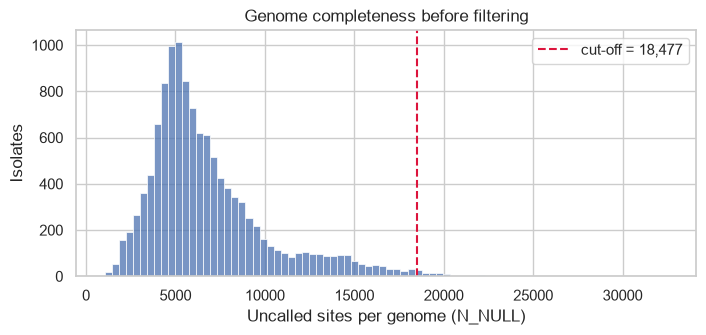

Isolates above the cut-off: 99
Lineages kept: {'Lineage 4': 5955, 'Lineage 2': 4288, 'Lineage 3': 1052, 'Lineage 1': 671, 'Lineage 6': 6}


In [5]:
# Genome completeness: number of positions with no confident base call.
q1, q3 = iso.N_NULL.quantile([0.25, 0.75])
null_cutoff = q3 + 3 * (q3 - q1)
fig, ax = plt.subplots(figsize=(8, 3.2))
sns.histplot(iso.N_NULL, bins=80, ax=ax, color="#4c72b0")
ax.axvline(null_cutoff, color="crimson", ls="--", label=f"cut-off = {null_cutoff:,.0f}")
ax.set(xlabel="Uncalled sites per genome (N_NULL)", ylabel="Isolates",
       title="Genome completeness before filtering")
ax.legend()
plt.show()

print(f"Isolates above the cut-off: {(iso.N_NULL > null_cutoff).sum()}")
iso = iso[iso.N_NULL <= null_cutoff]
log("Genome not extreme in uncalled sites", len(iso))

# lineage label used throughout: SNP-IT lineage, falling back to Mykrobe
iso["lineage"] = iso.LINEAGE_NAME.fillna(iso.MYKROBE_LINEAGE_NAME_1).replace({"Unknown": np.nan})
iso = iso.set_index("UNIQUEID")
print("Lineages kept:", iso.lineage.value_counts(dropna=False).to_dict())

In [6]:
# Mutation-level filters
m = muts_raw[muts_raw.UNIQUEID.isin(iso.index)].copy()
mut_log = [("Mutation rows for kept isolates", len(m))]
m = m[m.IS_FILTER_PASS.astype(bool)]
mut_log.append(("Passed the variant-call filter", len(m)))
m = m[~m.IS_NULL.astype(bool)]
mut_log.append(("Not a null (uncalled) site", len(m)))
m = m[~m.IS_HET.astype(bool)]
mut_log.append(("Not a mixed call", len(m)))
m = m.drop_duplicates(["UNIQUEID", "GENE", "MUTATION"])
mut_log.append(("Duplicates removed", len(m)))
display(pd.DataFrame(mut_log, columns=["step", "mutation rows"]))


def effect(row):
    if row.IS_INDEL:
        return "indel"
    if row.IN_PROMOTER:
        return "promoter"
    if row.ELEMENT_TYPE == "RNA":
        return "rRNA"
    if row.IS_SYNONYMOUS:
        return "synonymous"
    if str(row.MUTATION).endswith("!"):
        return "stop gained"
    return "missense"


m["effect"] = [effect(r) for r in m.itertuples()]
m["mut_id"] = m.GENE + "_" + m.MUTATION
print(m.effect.value_counts().to_dict())
print(f"{m.mut_id.nunique():,} distinct mutations in {m.GENE.nunique()} genes")

,step,mutation rows
0,Mutation rows for kept isolates,591807
1,Passed the variant-call filter,581431
2,Not a null (uncalled) site,218658
3,Not a mixed call,218658
4,Duplicates removed,218658


{'missense': 134264, 'synonymous': 71226, 'promoter': 6320, 'rRNA': 3280, 'indel': 2958, 'stop gained': 610}
8,772 distinct mutations in 43 genes


In [7]:
# Phenotypes: keep HIGH-quality R or S calls only
def mic_value(text):
    # turn an MIC string into a number; censored values move one dilution outward
    if pd.isna(text):
        return np.nan
    s = str(text)
    if s.startswith("<="):
        return float(s[2:])
    if s.startswith(">"):
        return float(s[1:]) * 2
    return float(s)


pheno = pheno_raw.set_index("UNIQUEID").loc[iso.index]
y_all, mic, pheno_rows = {}, {}, []
for d in DRUG_ORDER:
    b, q = pheno[f"{d}_BINARY_PHENOTYPE"], pheno[f"{d}_PHENOTYPE_QUALITY"]
    mic[d] = pheno[f"{d}_MIC"].map(mic_value)
    keep = (q == "HIGH") & b.isin(["R", "S"])
    y_all[d] = (b[keep] == "R").astype(int)
    pheno_rows.append({"drug": d, "with a call": b.notna().sum(), "intermediate": (b == "I").sum(),
                       "HIGH quality R/S": keep.sum(), "resistant": y_all[d].sum(),
                       "% resistant": round(100 * y_all[d].mean(), 1)})
mic = pd.DataFrame(mic)
pheno_table = pd.DataFrame(pheno_rows).set_index("drug")
display(pheno_table)
log("Isolates with at least one HIGH-quality R/S call",
    len(set().union(*[set(v.index) for v in y_all.values()])))
display(pd.DataFrame(qc_log))

,with a call,intermediate,HIGH quality R/S,resistant,% resistant
drug,,,,,
INH,11758,0,9260,4339,46.9
RIF,11789,0,8721,3373,38.7
RFB,11835,0,9771,3124,32.0
EMB,11843,1520,6436,1423,22.1
ETH,11822,946,8044,1161,14.4
LEV,11852,0,7558,1145,15.1
MXF,11881,0,6597,969,14.7
AMI,11762,0,8731,578,6.6
KAN,11819,0,9073,736,8.1


,step,isolates
0,All isolates with a phenotype row,12287
1,M. tuberculosis only,12273
2,No mixed-lineage call,12071
3,Genome not extreme in uncalled sites,11972
4,Isolates with at least one HIGH-quality R/S call,10606


In [8]:
# Biology check 1: the binary call must follow from the MIC and the ECOFF
rows = []
for d in DRUG_ORDER:
    y = y_all[d]
    called_R = (mic.loc[y.index, d] > ECOFF[d]).astype(int)
    rows.append({"drug": d, "agreement with MIC > ECOFF (%)": round(100 * (called_R == y).mean(), 2)})
display(pd.DataFrame(rows).set_index("drug").T)

# Biology check 2: drugs with the same target should show cross-resistance
for a, b in [("RIF", "RFB"), ("LEV", "MXF"), ("AMI", "KAN")]:
    both = y_all[a].index.intersection(y_all[b].index)
    ct = pd.crosstab(y_all[a][both].map({0: f"{a} S", 1: f"{a} R"}),
                     y_all[b][both].map({0: f"{b} S", 1: f"{b} R"}))
    print(f"\n{DRUGS[a]} vs {DRUGS[b]} (n = {len(both):,})")
    print(ct.to_string())

# Biology check 3: rpoB S450L, the most common rifampicin mutation worldwide
carriers = set(m.loc[m.mut_id == "rpoB_S450L", "UNIQUEID"])
y = y_all["RIF"]
in_c = y.index.isin(carriers)
print(f"\nrpoB S450L carriers resistant to rifampicin: {y[in_c].mean():.1%} (n = {in_c.sum():,}); "
      f"non-carriers: {y[~in_c].mean():.1%}")

drug,INH,RIF,RFB,EMB,ETH,LEV,MXF,AMI,KAN,LZD,BDQ,CFZ,DLM
agreement with MIC > ECOFF (%),100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0,100.0



Rifampicin vs Rifabutin (n = 8,187)
RFB_BINARY_PHENOTYPE  RFB R  RFB S
RIF_BINARY_PHENOTYPE              
RIF R                  2866    173
RIF S                    40   5108

Levofloxacin vs Moxifloxacin (n = 5,476)
MXF_BINARY_PHENOTYPE  MXF R  MXF S
LEV_BINARY_PHENOTYPE              
LEV R                   775    140
LEV S                    16   4545

Amikacin vs Kanamycin (n = 7,837)
KAN_BINARY_PHENOTYPE  KAN R  KAN S
AMI_BINARY_PHENOTYPE              
AMI R                   541     18
AMI S                   109   7169

rpoB S450L carriers resistant to rifampicin: 97.5% (n = 2,300); non-carriers: 17.6%


**Interpretation (Stage 3).**

* **Isolates.** No duplicated isolates or sequencing samples were found. 14 isolates were not
  *M. tuberculosis* (mostly the BCG vaccine strain), 202 had a mixed-lineage call, and 99 genomes
  had an extreme number of uncalled sites. **11,972 isolates** remain.
* **Mutation calls.** The most suspicious step: almost two-thirds of the mutation rows
  (581,431 → 218,658) are *null* calls. These are sites where the pipeline could not decide the
  base, mostly in hard-to-sequence regions and in the large ribosomal RNA genes. Treating them as
  mutations would invent thousands of fake variants, so they were removed. After filtering,
  60% of the 8,772 distinct mutations are seen in only one isolate, which is typical of
  bacterial genomes.
* **Phenotypes.** Keeping only HIGH-quality calls costs 21–46% of the results per drug
  (most for ethambutol, moxifloxacin and linezolid), but it removes readings where the plate
  methods disagreed.
* **Biology checks all pass.**
  * The binary calls agree 100% with "MIC above ECOFF". This is expected, because CRyPTIC derived
    them that way, but it confirms the MIC parsing is right.
  * Rifampicin/rifabutin, levofloxacin/moxifloxacin and amikacin/kanamycin share their targets,
    and the cross-tables show strong cross-resistance as expected (e.g. 541 of 559
    amikacin-resistant isolates are also kanamycin-resistant). The discordant cells are
    biologically sensible: 173 isolates are resistant to rifampicin but not rifabutin, which is
    known for some *rpoB* mutations.
  * 97.5% of the 2,300 isolates with *rpoB* S450L are rifampicin-resistant, against 17.6% of
    isolates without it.

## Stage 4: Exploratory data analysis

In [9]:
# Mutation matrix: one row per isolate, one column per mutation, 1 = carries it
M = (m.assign(v=1).pivot_table(index="UNIQUEID", columns="mut_id", values="v", aggfunc="max",
                               fill_value=0).reindex(iso.index, fill_value=0).astype(np.int8))
mut_info = (m.drop_duplicates("mut_id").set_index("mut_id")[["GENE", "MUTATION", "POSITION", "effect"]])
mut_info["carriers"] = M.sum()
print(f"Mutation matrix: {M.shape[0]:,} isolates x {M.shape[1]:,} mutations")
print(f"Mutations seen in only one isolate: {(mut_info.carriers == 1).sum():,} "
      f"({(mut_info.carriers == 1).mean():.0%})")

Mutation matrix: 11,972 isolates x 8,772 mutations
Mutations seen in only one isolate: 5,262 (60%)


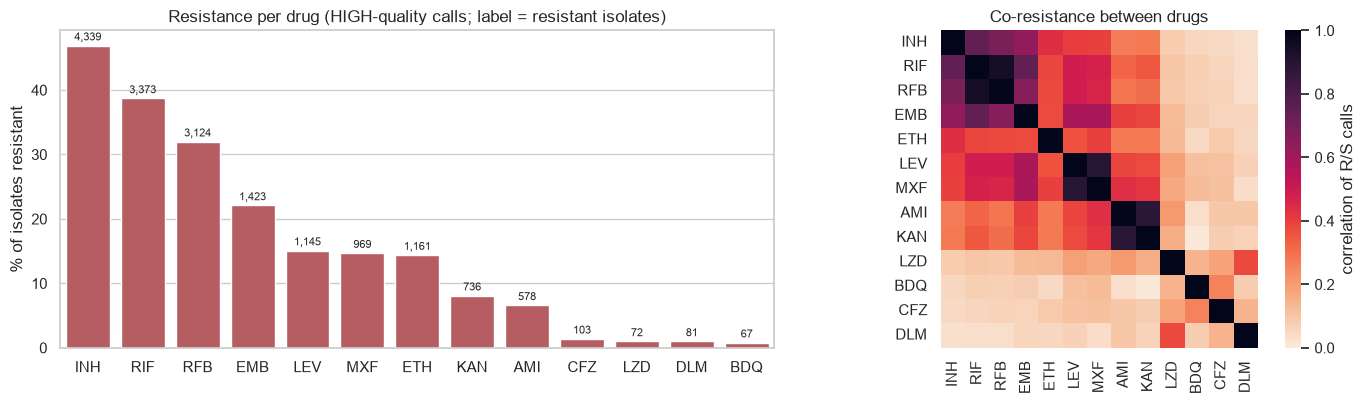

In [10]:
# Plot 1: how common resistance is, per drug
fig, axes = plt.subplots(1, 2, figsize=(14, 4.2), gridspec_kw={"width_ratios": [1.3, 1]})
pt = pheno_table.sort_values("% resistant", ascending=False)
sns.barplot(x=pt.index, y=pt["% resistant"], ax=axes[0], color="#c44e52")
for i, (p, n) in enumerate(zip(pt["% resistant"], pt["resistant"])):
    axes[0].text(i, p + 0.8, f"{n:,}", ha="center", fontsize=8)
axes[0].set(ylabel="% of isolates resistant", xlabel="",
            title="Resistance per drug (HIGH-quality calls; label = resistant isolates)")

# Plot 2: co-resistance between drugs
Y = pd.DataFrame(y_all)
co = Y.corr(min_periods=500)
sns.heatmap(co, cmap="rocket_r", vmin=0, vmax=1, ax=axes[1], square=True,
            cbar_kws={"label": "correlation of R/S calls"})
axes[1].set_title("Co-resistance between drugs")
plt.tight_layout()
plt.show()

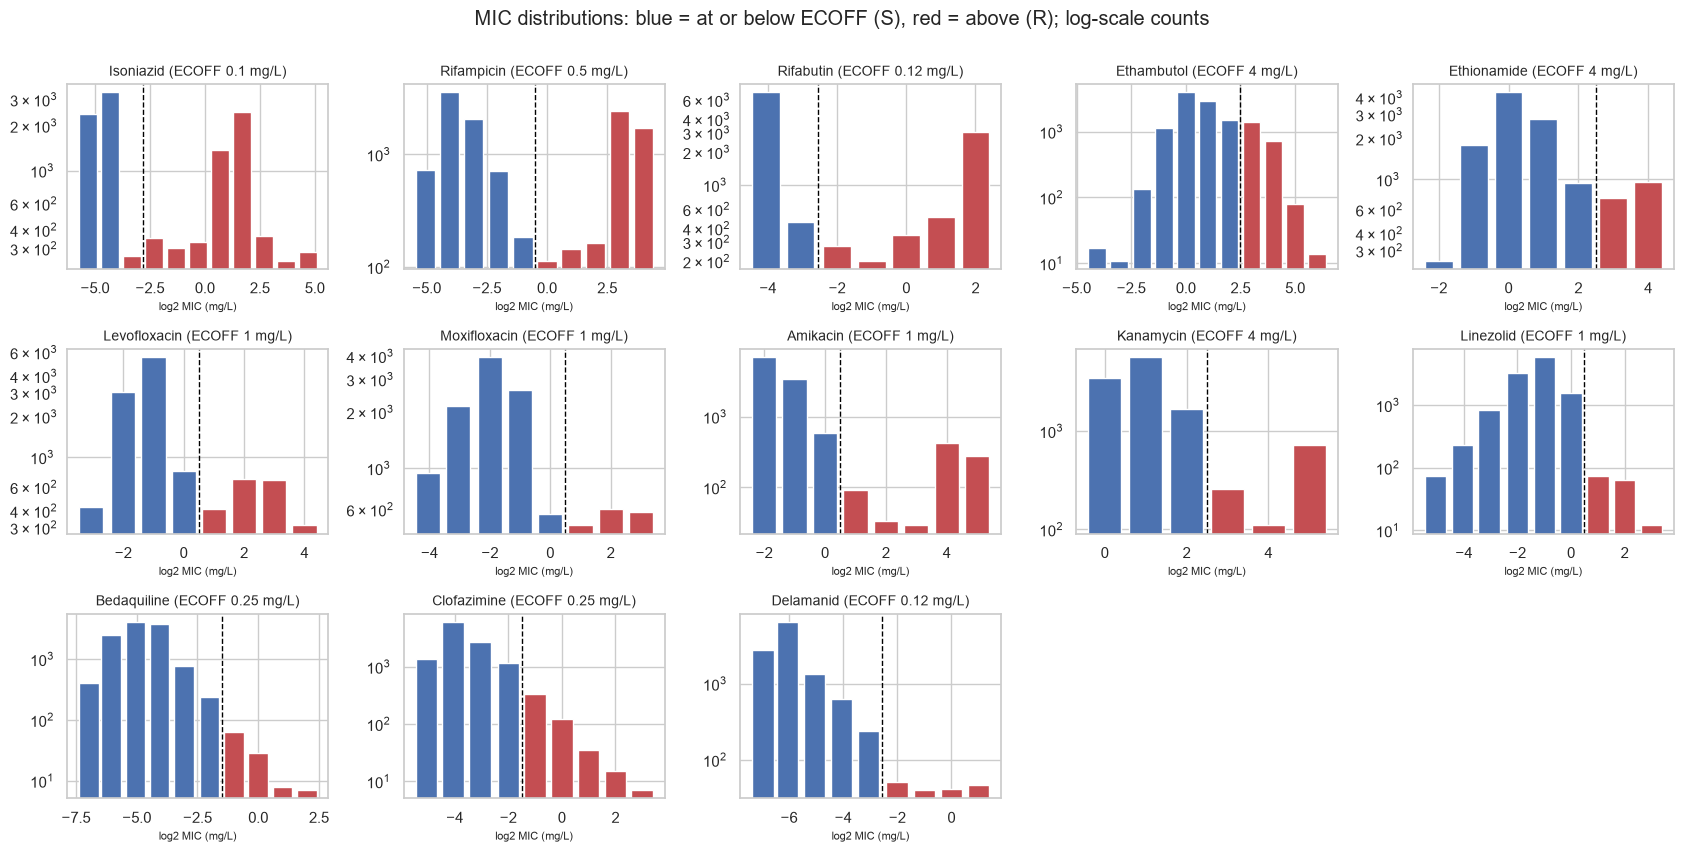

In [11]:
# Plot 3: MIC distributions, with the ECOFF that separates S from R
fig, axes = plt.subplots(3, 5, figsize=(17, 8.5))
for ax, d in zip(axes.flat, DRUG_ORDER):
    vals = np.log2(mic[d].dropna())
    counts = vals.round(2).value_counts().sort_index()
    colors = ["#c44e52" if v > np.log2(ECOFF[d]) + 1e-9 else "#4c72b0" for v in counts.index]
    ax.bar(counts.index, counts.values, width=0.8, color=colors)
    ax.axvline(np.log2(ECOFF[d]) + 0.5, color="black", ls="--", lw=1)
    ax.set_title(f"{DRUGS[d]} (ECOFF {ECOFF[d]} mg/L)", fontsize=10)
    ax.set_xlabel("log2 MIC (mg/L)", fontsize=8)
    ax.set_yscale("log")
for ax in list(axes.flat)[len(DRUG_ORDER):]:
    ax.axis("off")
fig.suptitle("MIC distributions: blue = at or below ECOFF (S), red = above (R); log-scale counts", y=1.0)
plt.tight_layout()
plt.show()

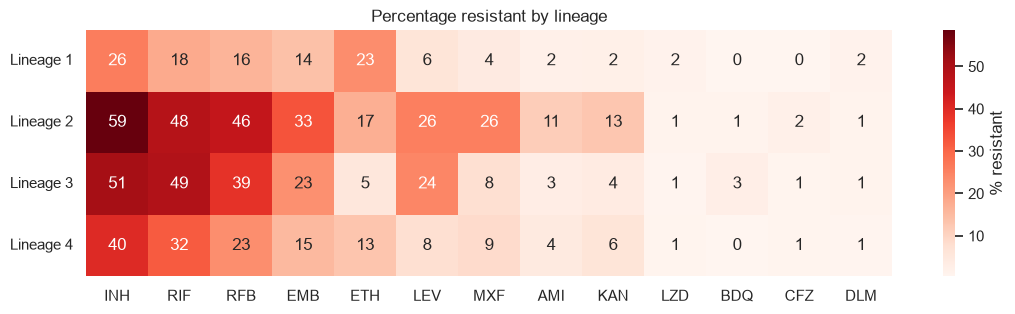

Isolates per lineage: {'Lineage 4': 5955, 'Lineage 2': 4288, 'Lineage 3': 1052, 'Lineage 1': 671}


In [12]:
# Plot 4: resistance by lineage
lin = iso.lineage.where(iso.lineage.isin(["Lineage 1", "Lineage 2", "Lineage 3", "Lineage 4"]))
by_lin = (Y.join(lin).groupby("lineage")[DRUG_ORDER].mean() * 100).round(1)
fig, ax = plt.subplots(figsize=(13, 3.2))
sns.heatmap(by_lin, annot=True, fmt=".0f", cmap="Reds", ax=ax, cbar_kws={"label": "% resistant"})
ax.set(title="Percentage resistant by lineage", ylabel="", xlabel="")
plt.show()
print("Isolates per lineage:", lin.value_counts().to_dict())

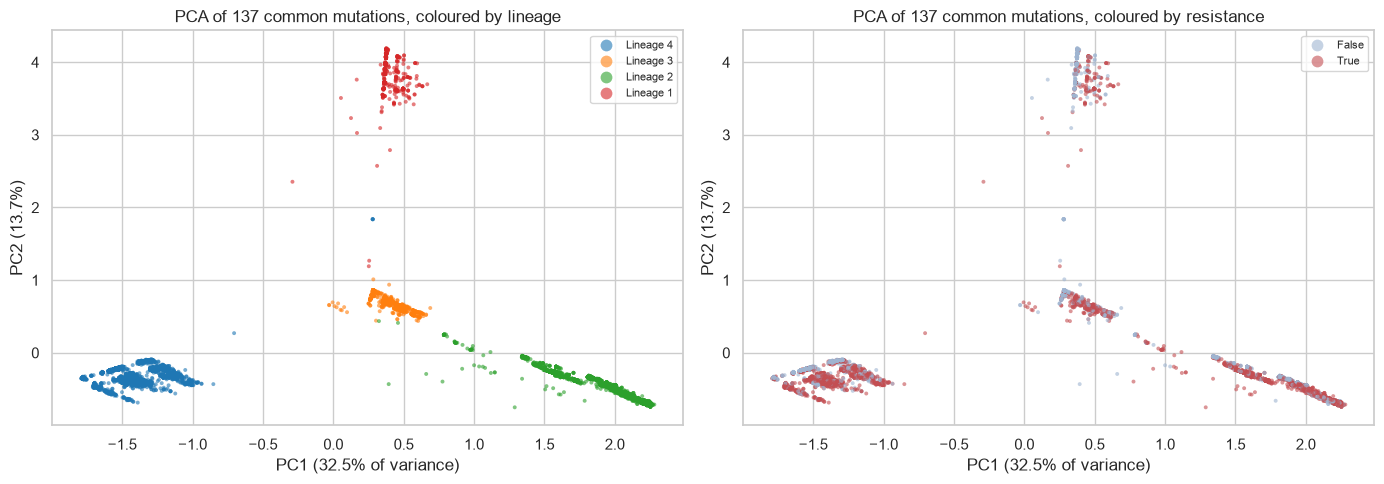

Mutations with the largest PC1 loadings: fgd1_F320F, gid_A205A, rpoB_A1075A, mmpL5_T794I, katG_R463L, rpsA_R212R, aftB_D397G, embA_C76C


In [13]:
# Plot 5: PCA of the mutation matrix (mutations in >= 1% of isolates), coloured by lineage
common = mut_info.index[mut_info.carriers >= 0.01 * len(M)]
pcs = PCA(n_components=2, random_state=SEED).fit(M[common])
xy = pcs.transform(M[common])
pc = pd.DataFrame(xy, index=M.index, columns=["PC1", "PC2"]).join(lin)
pc["INH or RIF resistant"] = (Y[["INH", "RIF"]].max(axis=1).reindex(pc.index) == 1)
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.scatterplot(data=pc.sample(frac=1, random_state=SEED), x="PC1", y="PC2", hue="lineage",
                s=8, alpha=0.6, linewidth=0, ax=axes[0], palette="tab10")
sns.scatterplot(data=pc.sample(frac=1, random_state=SEED), x="PC1", y="PC2",
                hue="INH or RIF resistant", s=8, alpha=0.6, linewidth=0, ax=axes[1],
                palette={False: "#9fb5d1", True: "#c44e52"})
ev = pcs.explained_variance_ratio_ * 100
for ax, t in zip(axes, ["coloured by lineage", "coloured by resistance"]):
    ax.set(xlabel=f"PC1 ({ev[0]:.1f}% of variance)", ylabel=f"PC2 ({ev[1]:.1f}%)", title=f"PCA of {len(common)} common mutations, {t}")
    ax.legend(markerscale=3, fontsize=8)
plt.tight_layout()
plt.show()

top_load = pd.Series(pcs.components_[0], index=common).abs().sort_values(ascending=False).head(8)
print("Mutations with the largest PC1 loadings:", ", ".join(top_load.index))

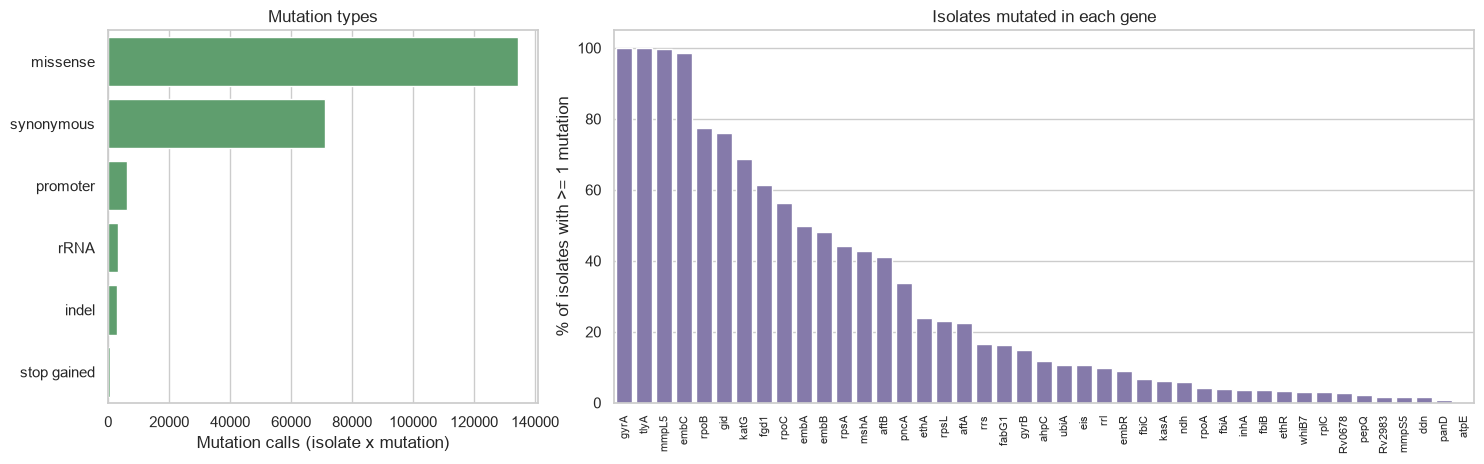

In [14]:
# Plot 6: what kinds of mutations are in the candidate genes, and how many per gene
fig, axes = plt.subplots(1, 2, figsize=(15, 4.8), gridspec_kw={"width_ratios": [1, 2]})
eff = m.effect.value_counts()
sns.barplot(x=eff.values, y=eff.index, ax=axes[0], color="#55a868")
axes[0].set(xlabel="Mutation calls (isolate x mutation)", ylabel="", title="Mutation types")
per_gene = m.groupby("GENE").UNIQUEID.nunique().sort_values(ascending=False) / len(iso) * 100
sns.barplot(x=per_gene.index, y=per_gene.values, ax=axes[1], color="#8172b2")
axes[1].set(ylabel="% of isolates with >= 1 mutation", xlabel="", title="Isolates mutated in each gene")
axes[1].tick_params(axis="x", rotation=90, labelsize=8)
plt.tight_layout()
plt.show()

**Interpretation (Stage 4).**

* **Resistance is common in this collection.** 47% of isolates are resistant to isoniazid and
  39% to rifampicin, far above the general TB population. CRyPTIC deliberately over-sampled
  drug-resistant TB, so these numbers are **not** prevalence estimates. Resistance to the newer
  drugs is rare (about 1%).
* **Co-resistance is strong.** Rifampicin and rifabutin (correlation close to 1) and the two
  fluoroquinolones behave almost as one drug. First-line resistances (INH, RIF, EMB) are also
  correlated with each other. That pattern is multidrug-resistant TB: resistance is acquired
  step by step in the same patients, so resistance to one drug "travels" with resistance to
  others. This will matter in Stages 5 and 7: a mutation can look linked to a drug only because
  it marks an MDR strain.
* **MIC distributions.** For isoniazid, rifampicin, rifabutin, amikacin and kanamycin the MICs
  form two separate peaks, one below and one above the ECOFF, so the R/S split is clean. For
  ethambutol and ethionamide there is no gap: the MICs form one continuous hump that the ECOFF
  cuts through, and bedaquiline and clofazimine show a tail rather than a second peak. Labels
  for these drugs will be noisier, because many isolates sit one dilution either side of the
  cut-off.
* **Lineage matters.** Lineage 2 (which includes the Beijing family) has the highest resistance
  to most first- and second-line drugs (59% isoniazid, 26% for each fluoroquinolone), with
  Lineage 3 similar for rifampicin. Lineage 1 has the lowest, except for ethionamide, where it
  is the highest (23%).
* **The PCA confirms the population structure.** The 137 common mutations separate the isolates
  into four tight groups that match the four lineages exactly. PC1 is driven by lineage-marker
  mutations such as *katG* R463L and the synonymous *rpoB* A1075A. Resistant isolates
  (right panel) are spread across all lineages, so resistance does not define the main axes of
  variation. **Any mutation that marks a lineage will look associated with resistance just
  because Lineage 2 is more resistant.** This is why Stage 5 adjusts for lineage.
* **Mutation types.** Missense changes are the most common, then synonymous ones. *rpoB*,
  *katG*, *gyrA* and *embB* are mutated in a large share of isolates, partly because of
  resistance and partly because of lineage polymorphisms.

## Stage 5: Core analysis: which mutations are linked to resistance?

For every drug, every mutation in that drug's candidate genes carried by at least 5 isolates with
a HIGH-quality result is tested with a 2 x 2 table:

| | Resistant | Susceptible |
|---|---|---|
| carries the mutation | a | b |
| does not carry it | c | d |

* **Odds ratio (OR)** = (a·d)/(b·c), with 0.5 added to every cell so zero cells do not give
  infinite values, and a 95% confidence interval on the log scale.
* **Fisher's exact test** p-value, then the **Benjamini–Hochberg false discovery rate (FDR)**
  across every test for every drug (many tests are run, so raw p-values would give many false hits).
* **Positive predictive value (PPV)** = a/(a+b): of the isolates that carry the mutation, the
  fraction that are resistant, with a Wilson 95% interval.
* **Sensitivity** = a/(a+c): the fraction of all resistant isolates that carry it.

We call a mutation **strongly linked** to resistance when FDR < 0.05, the lower bound of the OR
interval is above 1, and PPV ≥ 0.8. **Associated** means the first two conditions hold but
PPV < 0.8.

In [15]:
MIN_CARRIERS = 5
records = []
for d in DRUG_ORDER:
    y = y_all[d]
    cols = mut_info.index[mut_info.GENE.isin(DRUG_GENES[d])]
    X = M.loc[y.index, cols]
    n_carry = X.sum()
    X = X.loc[:, n_carry >= MIN_CARRIERS]
    a = X.T.values @ y.values
    n = X.sum().values
    b = n - a
    c = y.sum() - a
    dd = (len(y) - y.sum()) - b
    for j, mid in enumerate(X.columns):
        p = fisher_exact([[a[j], b[j]], [c[j], dd[j]]])[1]
        lo_or = np.log(((a[j] + .5) * (dd[j] + .5)) / ((b[j] + .5) * (c[j] + .5)))
        se = np.sqrt(1 / (a[j] + .5) + 1 / (b[j] + .5) + 1 / (c[j] + .5) + 1 / (dd[j] + .5))
        ppv_lo, ppv_hi = proportion_confint(a[j], n[j], method="wilson")
        records.append({"drug": d, "mut_id": mid, "gene": mut_info.at[mid, "GENE"],
                        "mutation": mut_info.at[mid, "MUTATION"], "effect": mut_info.at[mid, "effect"],
                        "R_carriers": a[j], "S_carriers": b[j], "OR": np.exp(lo_or),
                        "OR_low": np.exp(lo_or - 1.96 * se), "OR_high": np.exp(lo_or + 1.96 * se),
                        "p": p, "PPV": a[j] / n[j], "PPV_low": ppv_lo, "PPV_high": ppv_hi,
                        "sensitivity": a[j] / y.sum()})
assoc = pd.DataFrame(records)
assoc["FDR"] = multipletests(assoc.p, method="fdr_bh")[1]
sig = (assoc.FDR < 0.05) & (assoc.OR_low > 1)
assoc["class"] = np.select([sig & (assoc.PPV >= 0.8), sig], ["strongly linked", "associated"],
                           "not linked")
print(f"{len(assoc):,} mutation-drug tests on {assoc.mut_id.nunique():,} mutations")
display(assoc.groupby("drug")["class"].value_counts().unstack(fill_value=0).reindex(DRUG_ORDER))

1,113 mutation-drug tests on 768 mutations


class,associated,not linked,strongly linked
drug,,,
INH,5,46,33
RIF,12,65,96
RFB,10,66,101
EMB,19,123,35
ETH,17,62,25
LEV,10,52,10
MXF,12,44,7
AMI,2,47,1
KAN,6,43,2


In [16]:
# Results table: the strongly linked mutations, ranked by how many resistant isolates carry them
fmt = {"OR": "{:.1f}", "OR_low": "{:.1f}", "PPV": "{:.2f}", "sensitivity": "{:.1%}", "FDR": "{:.1e}"}
strong = (assoc[assoc["class"] == "strongly linked"]
          .sort_values(["drug", "R_carriers"], ascending=[True, False]))
top = (strong.groupby("drug", sort=False).head(5)
       .assign(drug=lambda t: pd.Categorical(t.drug, DRUG_ORDER, ordered=True))
       .sort_values(["drug", "R_carriers"], ascending=[True, False]))
cols = ["drug", "gene", "mutation", "effect", "R_carriers", "S_carriers", "OR", "OR_low", "PPV",
        "sensitivity", "FDR"]
print("Top 5 strongly linked mutations per drug")
display(top[cols].style.format(fmt).hide(axis="index"))

Top 5 strongly linked mutations per drug


drug,gene,mutation,effect,R_carriers,S_carriers,OR,OR_low,PPV,sensitivity,FDR
INH,katG,S315T,missense,3403,35,500.3,356.8,0.99,78.4%,0.0e+00
INH,fabG1,c-15t,promoter,798,20,53.9,34.7,0.98,18.4%,5.9e-245
INH,fabG1,g-17t,promoter,178,7,28.1,13.5,0.96,4.1%,3.7e-48
INH,fabG1,L203L,synonymous,104,4,27.0,10.5,0.96,2.4%,2.9e-28
INH,fabG1,t-8c,promoter,50,5,10.5,4.4,0.91,1.2%,4.9e-11
RIF,rpoB,S450L,missense,2242,58,179.2,137.2,0.97,66.5%,0.0e+00
RIF,rpoB,D435V,missense,398,14,49.3,29.1,0.97,11.8%,1.1e-146
RIF,rpoC,V483A,missense,183,6,47.3,21.6,0.97,5.4%,2.6e-66
RIF,rpoC,I491V,missense,172,8,33.9,17.0,0.96,5.1%,1.7e-59
RIF,rpoC,V483G,missense,150,3,71.3,24.7,0.98,4.4%,9.1e-57


In [17]:
# Overall ranking: the mutations linked to resistance in the most isolates (any drug)
overall = (strong.sort_values("R_carriers", ascending=False)
           .drop_duplicates("mut_id").head(15))
overall["drugs"] = overall.mut_id.map(strong.groupby("mut_id").drug.apply(lambda s: ", ".join(s)))
print("The 15 mutations linked to resistance in the most isolates")
display(overall[["gene", "mutation", "effect", "drugs", "R_carriers", "S_carriers", "OR",
                 "PPV", "FDR"]].style.format(fmt).hide(axis="index"))

The 15 mutations linked to resistance in the most isolates


gene,mutation,effect,drugs,R_carriers,S_carriers,OR,PPV,FDR
katG,S315T,missense,INH,3403,35,500.3,0.99,0.0e+00
rpoB,S450L,missense,"RFB, RIF",2242,58,179.2,0.97,0.0e+00
fabG1,c-15t,promoter,"ETH, INH",798,20,53.9,0.98,5.9e-245
embB,M306V,missense,EMB,585,36,95.2,0.94,0.0e+00
rrs,a1401g,rRNA,"AMI, KAN",487,27,590.5,0.95,0.0e+00
gyrA,D94G,missense,"LEV, MXF",444,44,90.7,0.91,0.0e+00
rpoB,D435V,missense,RIF,398,14,49.3,0.97,1.1e-146
gyrA,A90V,missense,LEV,250,30,58.5,0.89,5.4e-176
rpoC,V483A,missense,"RFB, RIF",188,5,77.5,0.97,3.7e-85
fabG1,g-17t,promoter,INH,178,7,28.1,0.96,3.7e-48


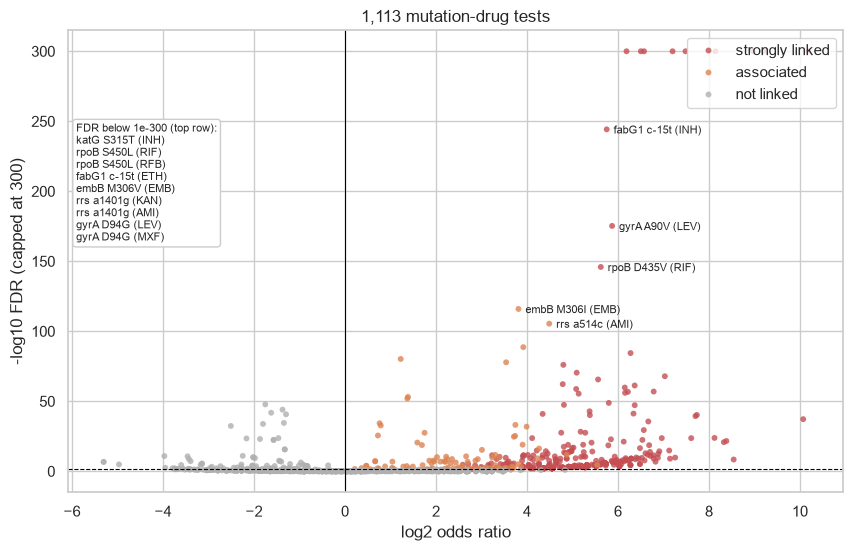

528 tests significant; 78 of them with OR < 1 (mutation more common in susceptible isolates). The strongest of those:


drug,gene,mutation,effect,R_carriers,S_carriers,OR,FDR,most common in
RIF,rpoB,D103D,synonymous,158,761,0.3,1.8e-48,Lineage 4
RIF,rpoC,G594E,missense,286,1036,0.4,9.3e-45,Lineage 4
RFB,rpoB,D103D,synonymous,154,917,0.3,1.6e-42,Lineage 4
RFB,rpoC,G594E,missense,278,1287,0.4,2.0e-41,Lineage 4
INH,mshA,N111S,missense,251,664,0.4,3.0e-35,Lineage 4
EMB,embC,V981L,missense,90,959,0.3,1.5e-34,Lineage 4
RIF,rpoC,P601L,missense,37,321,0.2,4.3e-33,Lineage 1
INH,kasA,T6T,synonymous,131,390,0.4,2.1e-24,Lineage 1


In [18]:
# Volcano plot: effect size against evidence for every test
fig, ax = plt.subplots(figsize=(10, 6))
pal = {"strongly linked": "#c44e52", "associated": "#dd8452", "not linked": "#b0b0b0"}
plot = assoc.assign(log2OR=np.log2(assoc.OR), mlogFDR=-np.log10(assoc.FDR.clip(lower=1e-300)))
sns.scatterplot(data=plot, x="log2OR", y="mlogFDR", hue="class", palette=pal, s=18,
                linewidth=0, alpha=0.8, ax=ax)
ax.axhline(-np.log10(0.05), ls="--", c="black", lw=0.8)
ax.axvline(0, c="black", lw=0.8)
capped = plot[plot.mlogFDR >= 300].sort_values("R_carriers", ascending=False)
for _, r in plot[plot.mlogFDR < 300].sort_values("mlogFDR", ascending=False).head(5).iterrows():
    ax.annotate(f"{r.gene} {r.mutation} ({r.drug})", (r.log2OR, r.mlogFDR), fontsize=8,
                xytext=(5, -3), textcoords="offset points")
ax.text(0.01, 0.80, "FDR below 1e-300 (top row):\n" +
        "\n".join(f"{r.gene} {r.mutation} ({r.drug})" for r in capped.itertuples()),
        transform=ax.transAxes, fontsize=8, va="top",
        bbox=dict(boxstyle="round", fc="white", ec="#cccccc"))
ax.set(xlabel="log2 odds ratio", ylabel="-log10 FDR (capped at 300)",
       title=f"{len(assoc):,} mutation-drug tests")
ax.legend(loc="upper right")
plt.show()

neg = assoc[(assoc.FDR < 0.05) & (assoc.OR_high < 1)].sort_values("FDR").head(8).copy()
neg["most common in"] = [M.loc[lin.dropna().index, mid].groupby(lin.dropna()).mean().idxmax() for mid in neg.mut_id]
print(f"{(assoc.FDR < 0.05).sum()} tests significant; {((assoc.FDR < 0.05) & (assoc.OR_high < 1)).sum()} of them "
      "with OR < 1 (mutation more common in susceptible isolates). The strongest of those:")
display(neg[["drug", "gene", "mutation", "effect", "R_carriers", "S_carriers", "OR", "FDR", "most common in"]]
        .style.format(fmt).hide(axis="index"))

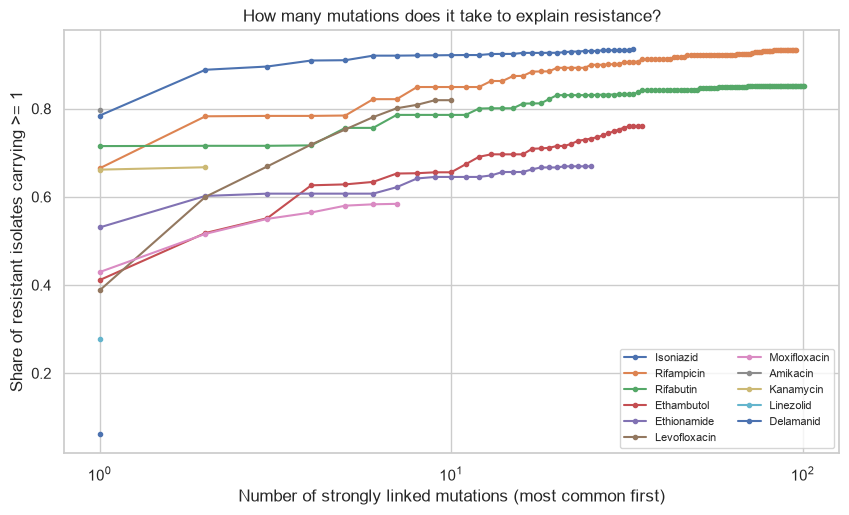

,strong mutations,sensitivity,specificity,top mutation,share explained by top mutation
drug,,,,,
INH,33,93.5%,98.2%,katG_S315T,78.4%
RIF,96,93.2%,98.1%,rpoB_S450L,66.5%
RFB,101,85.2%,98.6%,rpoB_S450L,71.5%
EMB,35,76.0%,97.3%,embB_M306V,41.1%
ETH,25,66.9%,99.0%,fabG1_c-15t,53.1%
LEV,10,81.9%,98.5%,gyrA_D94G,38.8%
MXF,7,58.4%,98.7%,gyrA_D94G,42.9%
AMI,1,79.8%,99.7%,rrs_a1401g,79.8%
KAN,2,66.7%,99.7%,rrs_a1401g,66.2%


In [19]:
# How much resistance do the strongly linked mutations explain?
# Add mutations in order of resistant carriers; track the share of R and S isolates that carry >= 1.
fig, ax = plt.subplots(figsize=(10, 5.5))
explained = []
for d in DRUG_ORDER:
    y = y_all[d]
    ms = strong[strong.drug == d].sort_values("R_carriers", ascending=False).mut_id.tolist()
    if not ms:
        explained.append({"drug": d, "strong mutations": 0, "sensitivity": 0.0, "specificity": 1.0})
        continue
    X = M.loc[y.index, ms]
    cum = X.cumsum(axis=1).clip(upper=1)
    sens = [(cum.iloc[:, k][y == 1]).mean() for k in range(len(ms))]
    ax.plot(range(1, len(ms) + 1), sens, marker="o", ms=3, label=DRUGS[d])
    hit = cum.iloc[:, -1]
    explained.append({"drug": d, "strong mutations": len(ms), "sensitivity": hit[y == 1].mean(),
                      "specificity": 1 - hit[y == 0].mean(), "top mutation": ms[0],
                      "share explained by top mutation": X.iloc[:, 0][y == 1].mean()})
ax.set_xscale("log")
ax.set(xlabel="Number of strongly linked mutations (most common first)",
       ylabel="Share of resistant isolates carrying >= 1",
       title="How many mutations does it take to explain resistance?")
ax.legend(ncol=2, fontsize=8)
plt.show()
explained = pd.DataFrame(explained).set_index("drug")
display(explained.style.format({"sensitivity": "{:.1%}", "specificity": "{:.1%}",
                                "share explained by top mutation": "{:.1%}"}))

In [20]:
# Does the link survive once lineage is taken into account?
# Cochran-Mantel-Haenszel odds ratio, stratified by Lineage 1-4. Also tests the most common
# mutations that are NOT linked, to see whether they behave like lineage markers.
def cmh(d, mid):
    y = y_all[d]
    df = pd.DataFrame({"y": y, "x": M.loc[y.index, mid], "lin": lin.reindex(y.index)}).dropna()
    tables = []
    for _, g in df.groupby("lin"):
        t = pd.crosstab(g.x, g.y).reindex(index=[1, 0], columns=[1, 0], fill_value=0).values
        if t.sum(axis=1).min() > 0 and t.sum(axis=0).min() > 0:
            tables.append(t.astype(float))
    if not tables:
        return np.nan, np.nan
    st = StratifiedTable(tables, shift_zeros=True)
    return st.oddsratio_pooled, st.test_null_odds(correction=True).pvalue


picks = pd.concat([
    strong.sort_values("R_carriers", ascending=False).drop_duplicates("mut_id").head(12),
    assoc[assoc["class"] == "not linked"].assign(n=lambda t: t.R_carriers + t.S_carriers)
          .sort_values("n", ascending=False).drop_duplicates("mut_id").head(6),
    assoc[(assoc["class"] != "not linked") & (assoc.PPV < 0.6)].assign(n=lambda t: t.R_carriers + t.S_carriers)
          .sort_values("n", ascending=False).drop_duplicates("mut_id").head(6),
]).drop_duplicates(["drug", "mut_id"])
out = []
for r in picks.itertuples():
    or_cmh, p_cmh = cmh(r.drug, r.mut_id)
    lin_freq = M.loc[lin.dropna().index, r.mut_id].groupby(lin.dropna()).mean()
    out.append({"drug": r.drug, "gene": r.gene, "mutation": r.mutation, "class": r[assoc.columns.get_loc("class") + 1],
                "crude OR": r.OR, "lineage-adjusted OR": or_cmh, "CMH p": p_cmh,
                "most common in": f"{lin_freq.idxmax()} ({lin_freq.max():.0%})",
                "least common in": f"{lin_freq.idxmin()} ({lin_freq.min():.0%})"})
lineage_check = pd.DataFrame(out)
display(lineage_check.style.format({"crude OR": "{:.2f}", "lineage-adjusted OR": "{:.2f}", "CMH p": "{:.1e}"})
        .hide(axis="index"))

drug,gene,mutation,class,crude OR,lineage-adjusted OR,CMH p,most common in,least common in
INH,katG,S315T,strongly linked,500.25,505.29,0.0e+00,Lineage 2 (53%),Lineage 1 (13%)
RIF,rpoB,S450L,strongly linked,179.23,171.92,0.0e+00,Lineage 2 (39%),Lineage 1 (11%)
INH,fabG1,c-15t,strongly linked,53.91,55.90,0.0e+00,Lineage 4 (11%),Lineage 3 (4%)
EMB,embB,M306V,strongly linked,95.22,73.90,0.0e+00,Lineage 2 (19%),Lineage 4 (5%)
KAN,rrs,a1401g,strongly linked,590.47,537.22,0.0e+00,Lineage 2 (11%),Lineage 1 (1%)
LEV,gyrA,D94G,strongly linked,90.70,63.50,0.0e+00,Lineage 2 (14%),Lineage 1 (2%)
RIF,rpoB,D435V,strongly linked,49.27,59.88,0.0e+00,Lineage 4 (5%),Lineage 1 (0%)
LEV,gyrA,A90V,strongly linked,58.55,36.23,0.0e+00,Lineage 2 (7%),Lineage 1 (3%)
RFB,rpoC,V483A,strongly linked,77.53,51.70,0.0e+00,Lineage 2 (4%),Lineage 1 (0%)
INH,fabG1,g-17t,strongly linked,28.11,24.86,0.0e+00,Lineage 2 (4%),Lineage 1 (0%)


In [21]:
# "Solo" analysis: isolates whose only non-neutral mutation in the drug's genes is the one tested.
# This removes the chance that a mutation looks linked only because it travels with a real one.
# Neutral = seen in >= 20 isolates without any association, or synonymous and never associated
# (a few synonymous changes are linked, e.g. fabG1 L203L, which creates an alternative promoter).
linked_any = set(assoc.loc[assoc["class"] != "not linked", "mut_id"])
neutral = set(assoc.loc[(assoc["class"] == "not linked") & (assoc.R_carriers + assoc.S_carriers >= 20), "mut_id"])
neutral |= set(mut_info.index[mut_info.effect == "synonymous"]) - linked_any
neutral -= linked_any
solo_rows = []
for d in DRUG_ORDER:
    y = y_all[d]
    cols = [c for c in mut_info.index[mut_info.GENE.isin(DRUG_GENES[d])] if c not in neutral]
    X = M.loc[y.index, cols]
    only_one = X.sum(axis=1) == 1
    for r in strong[strong.drug == d].sort_values("R_carriers", ascending=False).head(5).itertuples():
        solo = only_one & (X[r.mut_id] == 1)
        n, k = solo.sum(), y[solo].sum()
        lo, hi = proportion_confint(k, n, method="wilson") if n else (np.nan, np.nan)
        solo_rows.append({"drug": d, "gene": r.gene, "mutation": r.mutation, "all carriers": r.R_carriers + r.S_carriers,
                          "solo carriers": n, "solo PPV": k / n if n else np.nan, "solo PPV 95% CI": f"{lo:.2f}-{hi:.2f}",
                          "overall PPV": r.PPV})
solo = pd.DataFrame(solo_rows)
display(solo.style.format({"solo PPV": "{:.2f}", "overall PPV": "{:.2f}"}).hide(axis="index"))

drug,gene,mutation,all carriers,solo carriers,solo PPV,solo PPV 95% CI,overall PPV
INH,katG,S315T,3438,834,1.00,0.99-1.00,0.99
INH,fabG1,c-15t,818,189,0.96,0.92-0.98,0.98
INH,fabG1,g-17t,185,31,0.84,0.67-0.93,0.96
INH,fabG1,L203L,108,10,0.80,0.49-0.94,0.96
INH,fabG1,t-8c,55,1,0.00,0.00-0.79,0.91
RIF,rpoB,S450L,2300,100,1.00,0.96-1.00,0.97
RIF,rpoB,D435V,412,45,1.00,0.92-1.00,0.97
RIF,rpoC,V483A,189,0,nan,nan-nan,0.97
RIF,rpoC,I491V,180,0,nan,nan-nan,0.96
RIF,rpoC,V483G,153,0,nan,nan-nan,0.98


**Interpretation (Stage 5): the answer to the research question.**

1. **A handful of mutations account for most resistance.** Out of 1,113 mutation–drug tests,
   528 were significant after FDR correction. The single strongest mutation per drug explains a
   large share of all resistant isolates on its own:

   | Mutation | Drug | Share of resistant isolates | PPV |
   |---|---|---|---|
   | *katG* S315T | isoniazid | 78% | 0.99 |
   | *rpoB* S450L | rifampicin | 67% | 0.97 |
   | *rrs* a1401g | amikacin | 80% | 0.94 |
   | *fabG1* c-15t (inhA promoter) | ethionamide | 53% | 0.92 |
   | *embB* M306V | ethambutol | 41% | 0.94 |
   | *gyrA* D94G | moxifloxacin | 43% | 0.88 |

   With all their strongly linked mutations, 93% of isoniazid-resistant and 93% of rifampicin-resistant isolates
   are explained, while only about 2% of susceptible isolates carry one.

2. **The most strongly linked mutations overall**, by number of resistant isolates and with
   odds ratios from about 50 to over 500:

   *katG* S315T > *rpoB* S450L > *fabG1* c-15t > *embB* M306V > *rrs* a1401g > *gyrA* D94G >
   *rpoB* D435V > *gyrA* A90V.

3. **The hypothesis holds for the first-line and second-line drugs, but not for the newer
   drugs.** For bedaquiline and clofazimine no mutation reaches the "strongly linked" bar. For
   linezolid (*rplC* C154R) and delamanid (*ddn* L49P), one rare mutation each explains only 28%
   and 6% of resistance. Resistance to these drugs is caused by many different, individually
   rare mutations (often loss of function in *Rv0678* or the *ddn*/*fbi* genes), which a
   mutation-by-mutation test cannot detect with around 100 resistant isolates.

4. **Lineage adjustment separates real effects from population structure.**
   * The top resistance mutations keep huge odds ratios inside every lineage (e.g. *katG* S315T:
     crude 500, adjusted 505).
   * Mutations that only mark a lineage lose their association once lineage is accounted for:
     *katG* R463L (associated with isoniazid crudely, OR 1.7) drops to an adjusted OR of 0.16,
     and *rpoB* A1075A to 0.67.
   * *gyrA* E21Q, S95T and G668D are carried by nearly every isolate (H37Rv, the reference genome,
     happens to carry the rare allele) and are not linked to fluoroquinolone resistance.
   * The 78 significant *negative* associations (OR < 1) are the same story in reverse. They are
     markers of Lineage 4 and Lineage 1 sub-groups, which are less often resistant.

5. **The solo analysis catches hitchhikers.** Several "strongly linked" mutations are never seen
   on their own: *rpoC* V483A, I491V and V483G (rifampicin), *inhA* I194T and I21T
   (ethionamide), *embC* A387V and *embB* T1082A (ethambutol). They always occur with another
   resistance mutation, so their high PPV is borrowed. The *rpoC* mutations are known
   **compensatory** mutations: they restore the growth of strains already made resistant by
   *rpoB* (see Stage 6). In contrast, *katG* S315T (834 solo isolates, solo PPV 1.00),
   *rpoB* S450L (100, 1.00), *fabG1* c-15t (189, 0.96), *rrs* a1401g (328, 0.92) and
   *embB* M306V (71, 0.94) are resistant even when they are the only mutation present, which is
   strong evidence that they cause resistance.

## Stage 6: Biological interpretation

Four methods link the statistical results back to biology:

1. **Effect on the MIC:** how far each top mutation raises the drug concentration needed to stop
   growth, compared with isolates that have no mutation in the drug's genes.
2. **Where the mutations fall in the protein** (domain and hotspot annotation).
3. **A drug–mutation network** (NetworkX): which mutations are shared by more than one drug, i.e.
   cross-resistance.
4. **Comparison with the literature** and the WHO catalogue of resistance mutations.

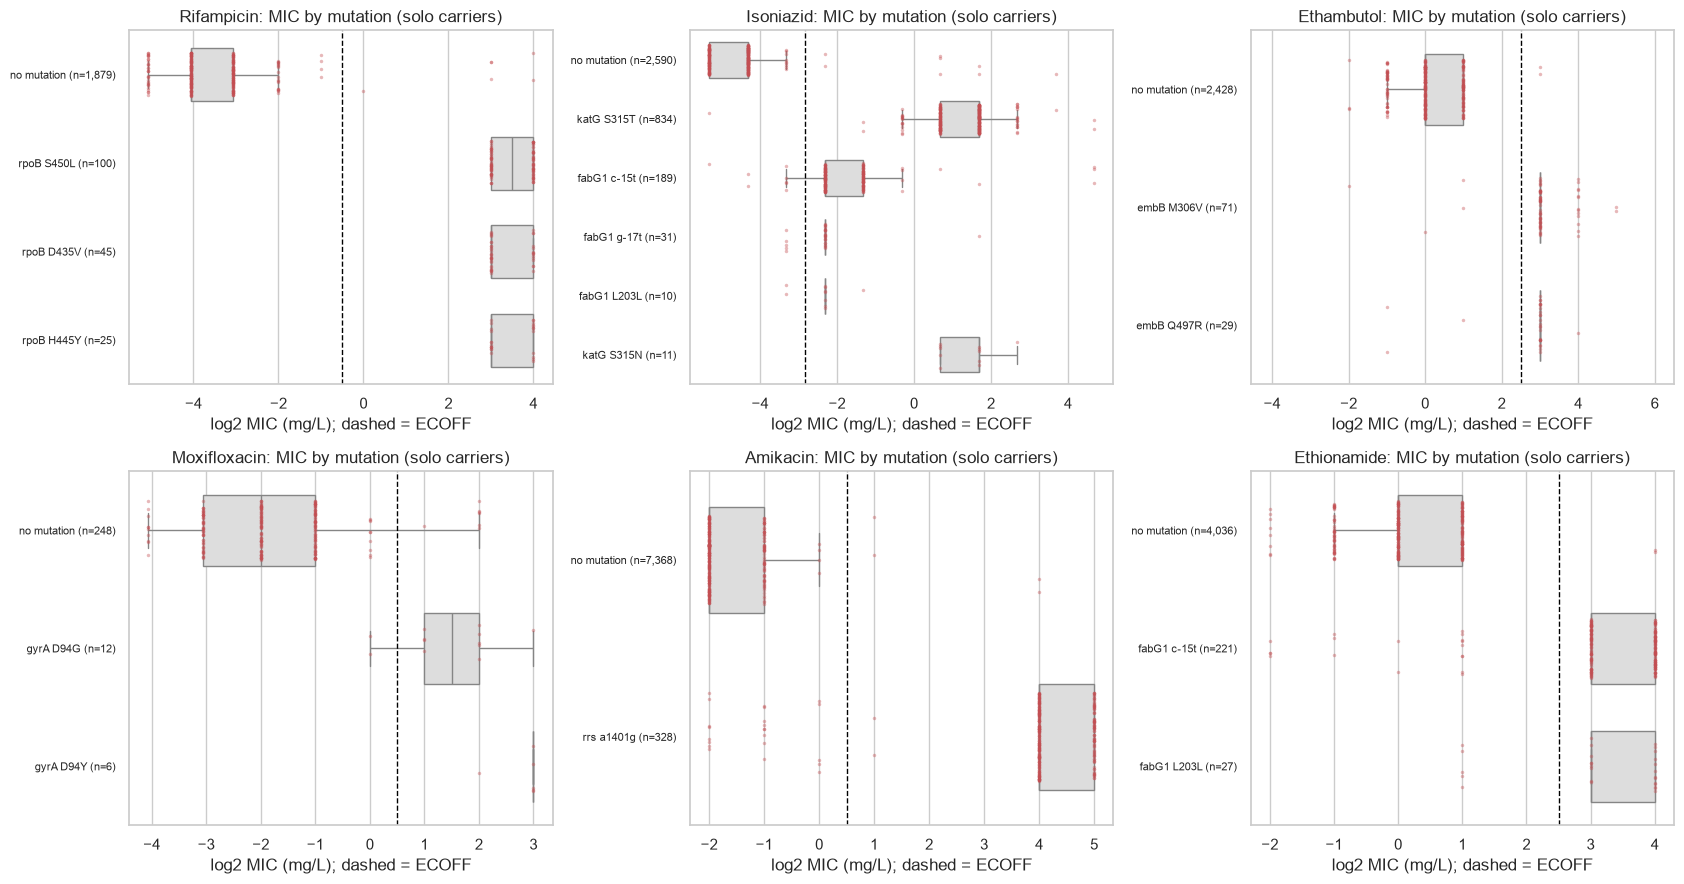

In [22]:
# 1. MIC of isolates carrying each top mutation alone, vs isolates with no mutation in the drug's genes
fig, axes = plt.subplots(2, 3, figsize=(17, 9))
for ax, d in zip(axes.flat, ["RIF", "INH", "EMB", "MXF", "AMI", "ETH"]):
    y = y_all[d]
    cols = [c for c in mut_info.index[mut_info.GENE.isin(DRUG_GENES[d])] if c not in neutral]
    X = M.loc[y.index, cols]
    groups = {"no mutation": X.index[X.sum(axis=1) == 0]}
    only_one = X.sum(axis=1) == 1
    for mid in strong[strong.drug == d].sort_values("R_carriers", ascending=False).mut_id.head(6):
        idx = X.index[only_one & (X[mid] == 1)]
        if len(idx) >= 5:
            groups[mid.replace("_", " ")] = idx
    df = pd.concat([pd.DataFrame({"group": g, "log2 MIC": np.log2(mic.loc[idx, d])}) for g, idx in groups.items()])
    sns.boxplot(data=df, y="group", x="log2 MIC", ax=ax, color="#dddddd", fliersize=0, width=0.6)
    sns.stripplot(data=df.sample(frac=1, random_state=SEED).groupby("group").head(300),
                  y="group", x="log2 MIC", ax=ax, size=2.5, alpha=0.4, jitter=0.25, color="#c44e52")
    ax.axvline(np.log2(ECOFF[d]) + 0.5, ls="--", c="black", lw=1)
    counts = df.group.value_counts()
    ax.set_yticks(range(len(groups)), [f"{g} (n={counts[g]:,})" for g in groups], fontsize=8)
    ax.set(title=f"{DRUGS[d]}: MIC by mutation (solo carriers)", ylabel="", xlabel="log2 MIC (mg/L); dashed = ECOFF")
plt.tight_layout()
plt.show()

In [23]:
# Cross-resistance check that only makes sense biologically:
# isoniazid is activated by KatG, ethionamide by EthA; both then inhibit InhA.
# So katG mutations should cause INH resistance only, while inhA-promoter (fabG1 c-15t) mutations
# should cause resistance to both.
both = y_all["INH"].index.intersection(y_all["ETH"].index)
rows = []
for mid in ["katG_S315T", "fabG1_c-15t", "inhA_S94A", "inhA_I21T"]:
    if mid not in M:
        continue
    car = both[M.loc[both, mid] == 1]
    rows.append({"mutation": mid.replace("_", " "), "carriers": len(car),
                 "% INH resistant": 100 * y_all["INH"][car].mean(),
                 "% ETH resistant": 100 * y_all["ETH"][car].mean(),
                 "median INH MIC": mic.loc[car, "INH"].median(),
                 "median ETH MIC": mic.loc[car, "ETH"].median()})
display(pd.DataFrame(rows).style.format(precision=1).hide(axis="index"))

mutation,carriers,% INH resistant,% ETH resistant,median INH MIC,median ETH MIC
katG S315T,2499,98.9,24.2,3.2,1.0
fabG1 c-15t,579,98.3,92.4,1.6,16.0
inhA S94A,22,95.5,100.0,1.6,16.0
inhA I21T,40,100.0,97.5,3.2,16.0


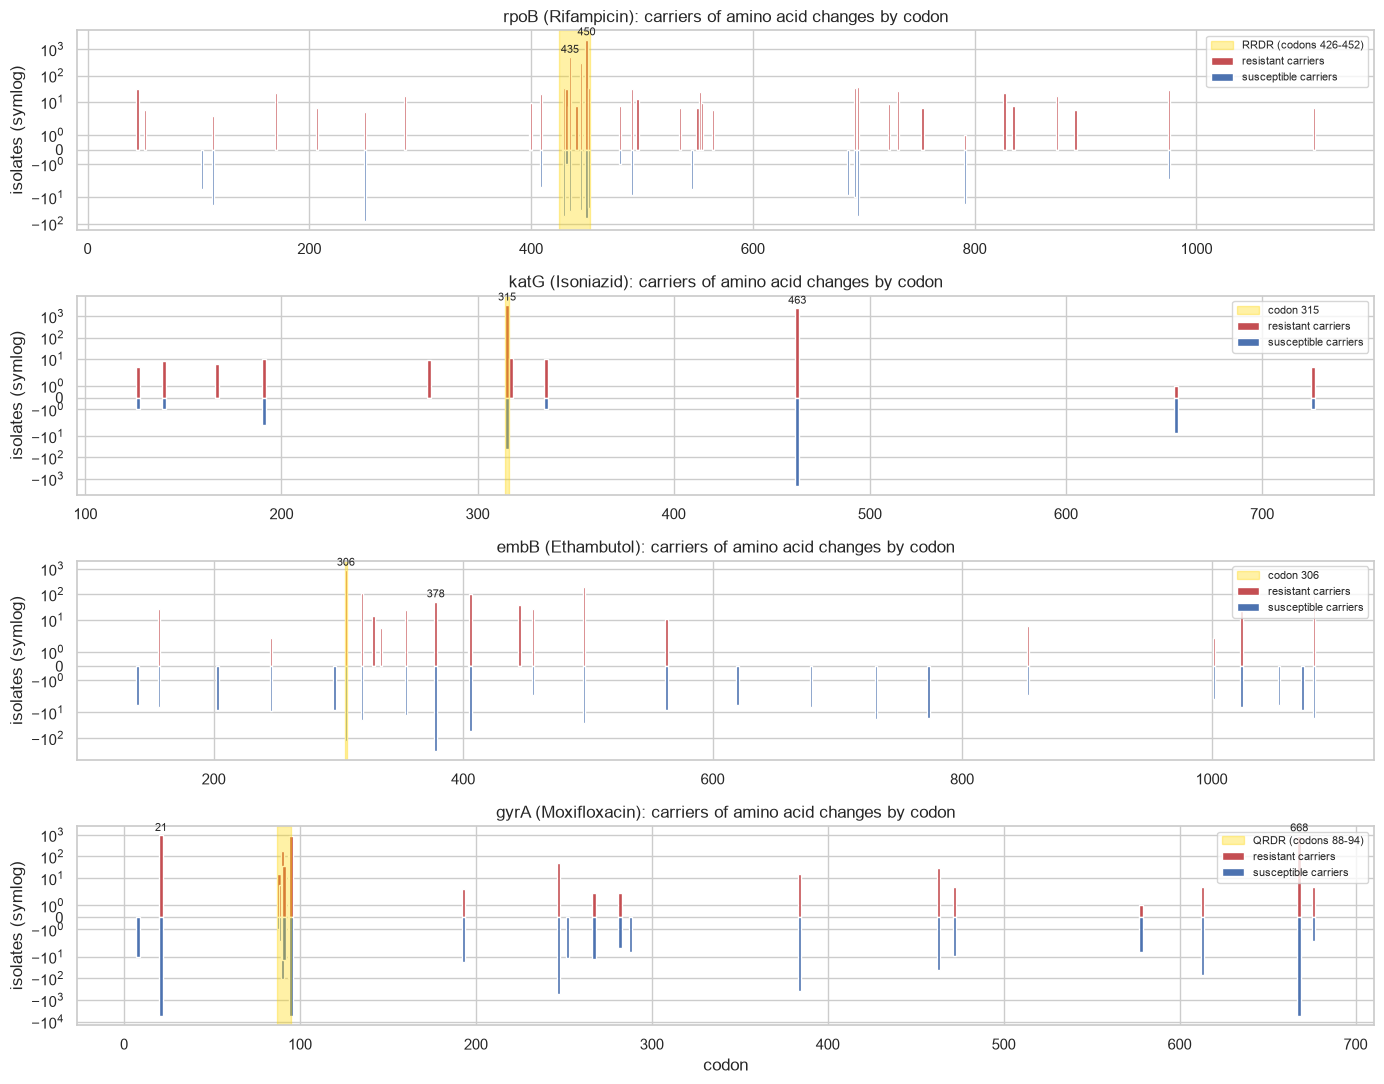

In [24]:
# 2. Where in the protein: resistant carriers per codon, for the four main target genes
regions = {"rpoB": (426, 452, "RRDR (codons 426-452)"), "katG": (315, 315, "codon 315"),
           "embB": (306, 306, "codon 306"), "gyrA": (88, 94, "QRDR (codons 88-94)")}
fig, axes = plt.subplots(4, 1, figsize=(14, 11))
drug_for = {"rpoB": "RIF", "katG": "INH", "embB": "EMB", "gyrA": "MXF"}
for ax, (gene, (s, e, lab)) in zip(axes, regions.items()):
    sub = assoc[(assoc.gene == gene) & (assoc.drug == drug_for[gene]) & (assoc.effect == "missense")].copy()
    sub["codon"] = sub.mutation.str.extract(r"(\d+)").astype(int)
    per_codon = sub.groupby("codon").agg(R=("R_carriers", "sum"), S=("S_carriers", "sum"))
    ax.bar(per_codon.index, per_codon.R, width=2, color="#c44e52", label="resistant carriers")
    ax.bar(per_codon.index, -per_codon.S, width=2, color="#4c72b0", label="susceptible carriers")
    ax.axvspan(s - 1, e + 1, color="gold", alpha=0.35, label=lab)
    for codon in per_codon.assign(t=per_codon.R + per_codon.S).nlargest(2, "t").index:
        ax.annotate(f"{codon}", (codon, per_codon.at[codon, "R"]), fontsize=8, ha="center",
                    xytext=(0, 3), textcoords="offset points")
    ax.set_yscale("symlog")
    ax.set(title=f"{gene} ({DRUGS[drug_for[gene]]}): carriers of amino acid changes by codon",
           ylabel="isolates (symlog)")
    ax.legend(fontsize=8, loc="upper right")
axes[-1].set_xlabel("codon")
plt.tight_layout()
plt.show()

10 drugs, 134 mutations, 200 links


,drugs in component,mutations,shared by all drugs in it,biggest shared (resistant carriers)
0,"RFB, RIF",64,55,"rpoB S450L, rpoC V483A, rpoC I491V, rpoC V483G"
1,"ETH, INH",35,6,"fabG1 c-15t, fabG1 L203L, inhA I194T, inhA I21T"
2,EMB,23,0,
3,"LEV, MXF",10,4,"gyrA D94G, gyrA D94N, gyrA D94Y, gyrA G88C"
4,"AMI, KAN",1,1,rrs a1401g
5,LZD,1,0,


Degree centrality of drug nodes (share of mutation nodes each drug is linked to):
{'RIF': 0.42, 'RFB': 0.413, 'INH': 0.196, 'EMB': 0.161, 'ETH': 0.091, 'LEV': 0.063, 'MXF': 0.035, 'AMI': 0.007, 'KAN': 0.007, 'LZD': 0.007}


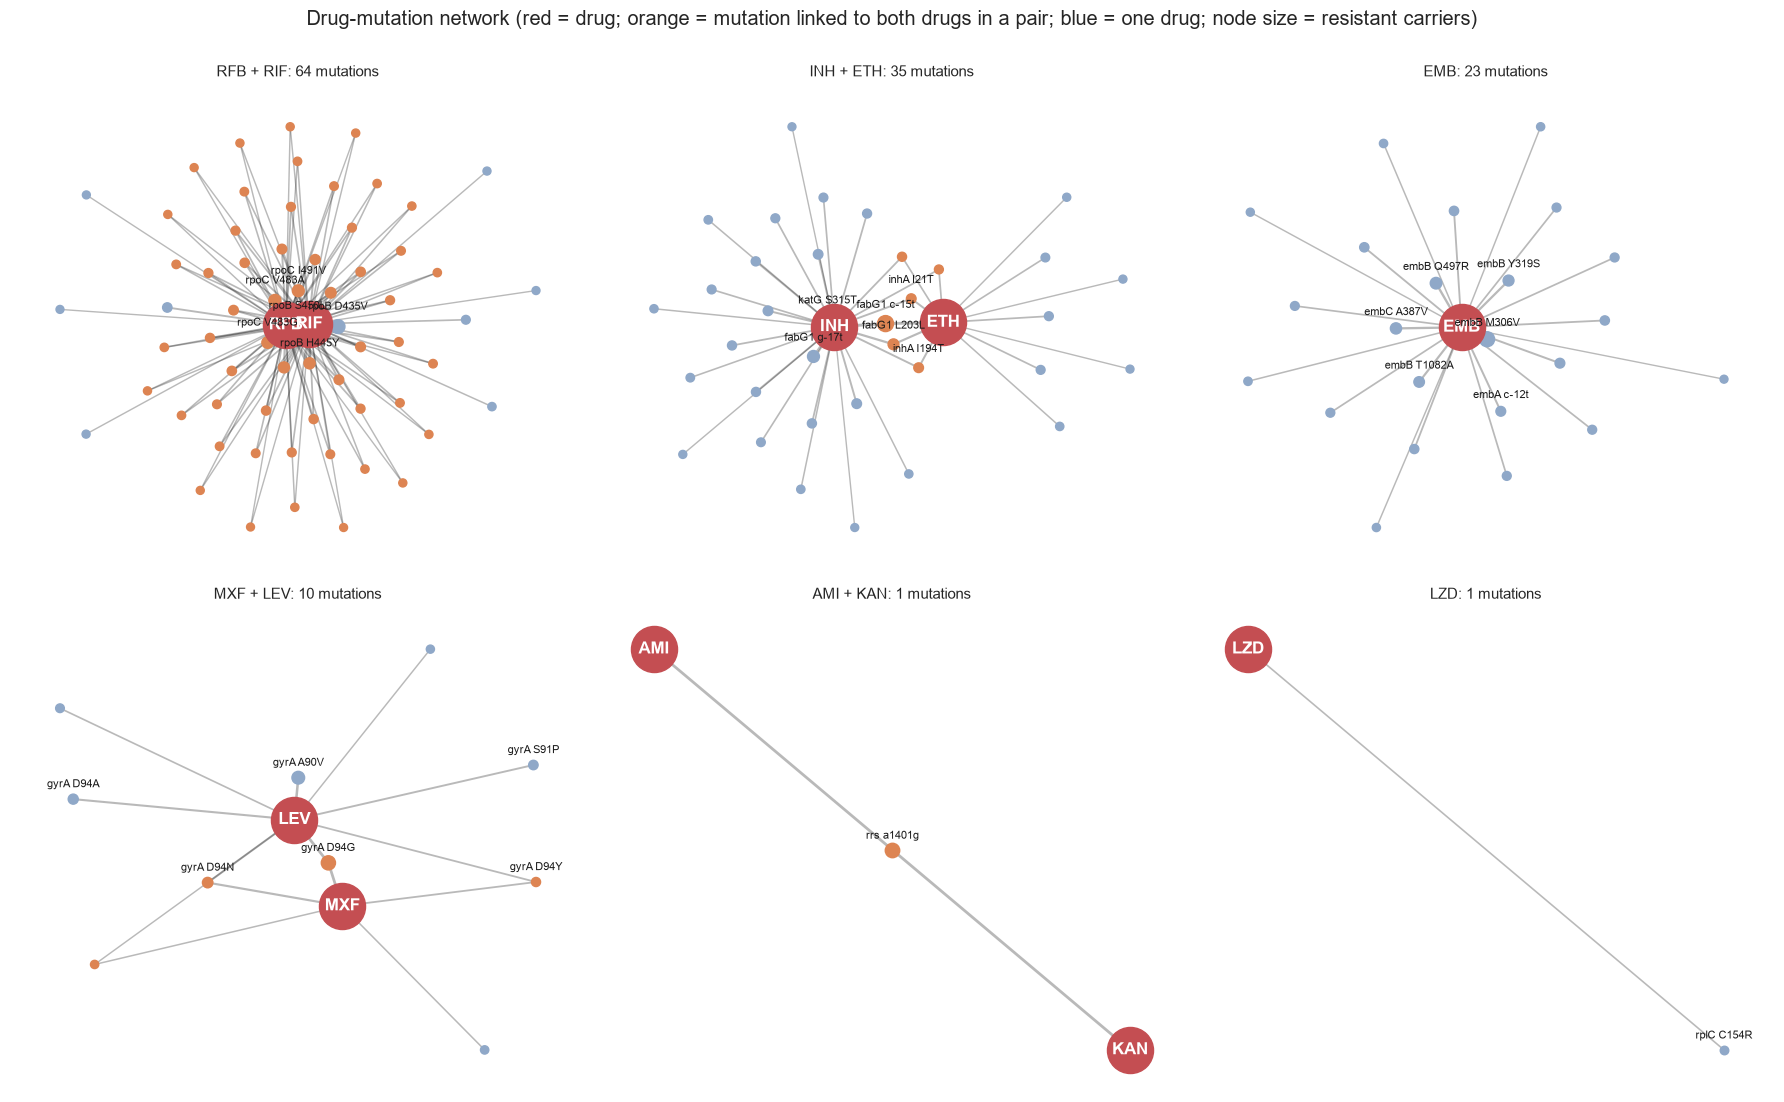

In [25]:
# 3. Drug-mutation network: an edge joins a drug to each mutation strongly linked to it
#    (mutations with >= 10 resistant carriers, to keep the figure readable)
G = nx.Graph()
edges = strong[strong.R_carriers >= 10]
for r in edges.itertuples():
    G.add_node(r.drug, kind="drug")
    G.add_node(r.mut_id, kind="mutation")
    G.add_edge(r.drug, r.mut_id, weight=r.R_carriers)
mut_nodes = [n for n, k in G.nodes(data="kind") if k == "mutation"]
drug_nodes = [n for n, k in G.nodes(data="kind") if k == "drug"]
shared = sorted([n for n in mut_nodes if G.degree(n) > 1], key=lambda n: -G.degree(n))
print(f"{len(drug_nodes)} drugs, {len(mut_nodes)} mutations, {G.number_of_edges()} links")

# connected components = groups of drugs that share resistance mutations
comps = sorted(nx.connected_components(G), key=len, reverse=True)
summary = []
for c in comps:
    drugs_c = sorted(set(c) & set(drug_nodes))
    muts_c = [n for n in c if n in mut_nodes]
    sh = [n for n in muts_c if n in shared]
    summary.append({"drugs in component": ", ".join(drugs_c), "mutations": len(muts_c),
                    "shared by all drugs in it": len(sh),
                    "biggest shared (resistant carriers)": ", ".join(
                        n.replace("_", " ") for n in sorted(sh, key=lambda n: -G[n][drugs_c[0]]["weight"])[:4])})
display(pd.DataFrame(summary))
print("Degree centrality of drug nodes (share of mutation nodes each drug is linked to):")
dc = nx.degree_centrality(G)
print({d: round(dc[d], 3) for d in sorted(drug_nodes, key=lambda d: -dc[d])})

# Draw each component in its own panel so the clusters stay readable
fig, axes = plt.subplots(2, 3, figsize=(18, 11))
for ax, c in zip(axes.flat, comps):
    H = G.subgraph(c)
    pos = nx.spring_layout(H, k=1.2 / np.sqrt(len(H)), seed=SEED, iterations=300)
    hm = [n for n in H if n in mut_nodes]
    hd = [n for n in H if n in drug_nodes]
    nx.draw_networkx_edges(H, pos, ax=ax, alpha=0.3, width=[0.4 + 0.6 * np.log10(H[u][v]["weight"]) for u, v in H.edges])
    nx.draw_networkx_nodes(H, pos, nodelist=hm, ax=ax,
                           node_color=["#dd8452" if n in shared else "#8fa8c8" for n in hm],
                           node_size=[20 + 4 * np.sqrt(max(H[n][d]["weight"] for d in H.neighbors(n))) for n in hm])
    nx.draw_networkx_nodes(H, pos, nodelist=hd, node_color="#c44e52", node_size=1100, ax=ax)
    nx.draw_networkx_labels(H, pos, labels={n: n for n in hd}, font_color="white", font_weight="bold", ax=ax)
    top_m = sorted(hm, key=lambda n: -max(H[n][d]["weight"] for d in H.neighbors(n)))[:6]
    nx.draw_networkx_labels(H, {n: pos[n] + np.array([0, 0.07]) for n in top_m},
                            labels={n: n.replace("_", " ") for n in top_m}, font_size=8, ax=ax)
    ax.set_title(f"{' + '.join(hd)}: {len(hm)} mutations", fontsize=11)
    ax.axis("off")
for ax in list(axes.flat)[len(comps):]:
    ax.axis("off")
fig.suptitle("Drug-mutation network (red = drug; orange = mutation linked to both drugs in a pair; "
             "blue = one drug; node size = resistant carriers)", y=1.0)
plt.tight_layout()
plt.show()

In [26]:
# 4. Comparison with the literature.
# Status of each top mutation as reported in published work (WHO catalogue 2021/2023,
# reviews of TB resistance mechanisms). Written by hand from the literature, not computed.
LITERATURE = {
    "rpoB_S450L": "Most common rifampicin mutation worldwide; RRDR; WHO: associated with resistance",
    "rpoB_H445Y": "RRDR; WHO: associated with resistance",
    "rpoB_H445D": "RRDR; WHO: associated with resistance",
    "rpoB_D435V": "RRDR; WHO: associated with resistance",
    "rpoB_D435Y": "RRDR 'borderline' mutation: modest MIC rise",
    "rpoB_L430P": "RRDR 'borderline' mutation: modest MIC rise, often missed by MGIT testing",
    "rpoB_S450W": "RRDR; WHO: associated with resistance",
    "katG_S315T": "Classic high-level isoniazid mutation; KatG no longer activates the prodrug",
    "katG_S315N": "Codon 315; WHO: associated with resistance",
    "fabG1_c-15t": "inhA promoter: overexpresses InhA; low-level INH plus ethionamide cross-resistance",
    "fabG1_g-17t": "inhA promoter; WHO: associated with resistance",
    "fabG1_L203L": "Silent change that creates an alternative inhA promoter; WHO: associated with resistance",
    "inhA_S94A": "InhA target change; INH and ETH",
    "inhA_": "InhA coding change; usually found together with an inhA-promoter mutation",
    "rpoC_": "rpoC: compensatory mutation that restores the fitness of rpoB-mutant strains; "
             "travels with rpoB mutations rather than causing resistance itself (Comas et al. 2012)",
    "rrs_c1402t": "16S rRNA C1402T; kanamycin (and capreomycin)",
    "ddn_": "ddn encodes the nitroreductase that activates delamanid; loss of function causes resistance",
    "embC_": "embC is in the ethambutol-target emb operon, but this mutation is not an established resistance mutation",
    "embB_M306V": "Most common ethambutol mutation (codon 306)",
    "embB_M306I": "Codon 306; ethambutol",
    "embB_Q497R": "embB; ethambutol",
    "embB_G406A": "embB; ethambutol",
    "embB_G406D": "embB; ethambutol",
    "gyrA_D94G": "QRDR; most common fluoroquinolone mutation",
    "gyrA_A90V": "QRDR; fluoroquinolones (lower-level)",
    "gyrA_D94N": "QRDR; fluoroquinolones",
    "gyrA_D94A": "QRDR; fluoroquinolones",
    "gyrA_S91P": "QRDR; fluoroquinolones",
    "gyrA_D94Y": "QRDR; fluoroquinolones",
    "rrs_a1401g": "16S rRNA A1401G; high-level amikacin and kanamycin resistance",
    "eis_c-14t": "eis promoter: aminoglycoside-modifying enzyme overexpressed; kanamycin",
    "eis_g-10a": "eis promoter; kanamycin",
    "ethA_": "ethA loss of function stops ethionamide activation",
    "Rv0678_": "Rv0678 (mmpR5) loss of function: MmpS5-MmpL5 efflux up; bedaquiline and clofazimine",
    "rplC_C154R": "Ribosomal protein L3; linezolid",
    "rrl_g2814t": "23S rRNA; linezolid",
    "gyrA_E21Q": "Phylogenetic marker (lineage polymorphism), not a resistance mutation",
    "gyrA_S95T": "Phylogenetic marker (lineage polymorphism), not a resistance mutation",
    "gyrA_G668D": "Phylogenetic marker (lineage polymorphism), not a resistance mutation",
    "katG_R463L": "Phylogenetic marker (lineage polymorphism), not a resistance mutation",
}


def literature(mid):
    if mid in LITERATURE:
        return LITERATURE[mid]
    for k, v in LITERATURE.items():
        if k.endswith("_") and mid.startswith(k):
            return v
    return "Not in our literature list"


lit = (strong.sort_values("R_carriers", ascending=False).groupby("drug").head(3)
       .assign(drug=lambda t: pd.Categorical(t.drug, DRUG_ORDER, ordered=True)).sort_values("drug"))
lit["literature"] = lit.mut_id.map(literature)
lit = lit.merge(solo[["drug", "gene", "mutation", "solo carriers", "solo PPV"]], on=["drug", "gene", "mutation"], how="left")
display(lit[["drug", "gene", "mutation", "R_carriers", "PPV", "solo carriers", "solo PPV", "literature"]]
        .style.format({"PPV": "{:.2f}", "solo PPV": "{:.2f}", "solo carriers": "{:.0f}"}, na_rep="-").hide(axis="index"))
unknown = lit.literature.str.contains("Not in our|not an established")
comp = lit.literature.str.contains("compensatory")
print(f"{len(lit)} top-3 mutations: {(~unknown & ~comp).sum()} are published resistance mutations, "
      f"{comp.sum()} are published compensatory mutations, {unknown.sum()} are not established in the literature")

drug,gene,mutation,R_carriers,PPV,solo carriers,solo PPV,literature
INH,katG,S315T,3403,0.99,834,1.00,Classic high-level isoniazid mutation; KatG no longer activates the prodrug
INH,fabG1,c-15t,798,0.98,189,0.96,inhA promoter: overexpresses InhA; low-level INH plus ethionamide cross-resistance
INH,fabG1,g-17t,178,0.96,31,0.84,inhA promoter; WHO: associated with resistance
RIF,rpoB,S450L,2242,0.97,100,1.00,Most common rifampicin mutation worldwide; RRDR; WHO: associated with resistance
RIF,rpoC,V483A,183,0.97,0,-,rpoC: compensatory mutation that restores the fitness of rpoB-mutant strains; travels with rpoB mutations rather than causing resistance itself (Comas et al. 2012)
RIF,rpoB,D435V,398,0.97,45,1.00,RRDR; WHO: associated with resistance
RFB,rpoC,I491V,174,0.94,0,-,rpoC: compensatory mutation that restores the fitness of rpoB-mutant strains; travels with rpoB mutations rather than causing resistance itself (Comas et al. 2012)
RFB,rpoC,V483A,188,0.97,0,-,rpoC: compensatory mutation that restores the fitness of rpoB-mutant strains; travels with rpoB mutations rather than causing resistance itself (Comas et al. 2012)
RFB,rpoB,S450L,2234,0.97,103,1.00,Most common rifampicin mutation worldwide; RRDR; WHO: associated with resistance
EMB,embB,Q497R,152,0.88,29,0.90,embB; ethambutol


26 top-3 mutations: 22 are published resistance mutations, 3 are published compensatory mutations, 1 are not established in the literature


**Interpretation (Stage 6).**

* **MIC.** Each top mutation, carried alone, moves the MIC well past the ECOFF.
  * *rpoB* S450L, D435V and H445Y push rifampicin from about 0.06 mg/L to 8–16 mg/L, at least a
    100-fold rise.
  * The two isoniazid mechanisms differ in size. *katG* S315T gives high-level resistance (median
    about 2–3 mg/L when carried alone). The inhA-promoter mutations *fabG1* c-15t and g-17t give
    low-level resistance (about 0.2 mg/L), just above the 0.1 mg/L ECOFF. This matters clinically: low-level
    isoniazid resistance can sometimes still be treated with a higher isoniazid dose.
  * *rrs* a1401g raises amikacin to the top of the plate's range.
* **Cross-resistance follows the drug's mechanism.** Isoniazid needs the KatG enzyme to be
  activated, ethionamide needs EthA, and both then block InhA.
  * *katG* S315T makes 98.9% of carriers isoniazid-resistant but only 24% ethionamide-resistant.
  * *fabG1* c-15t, which increases the amount of InhA, makes 98% isoniazid-resistant **and** 92%
    ethionamide-resistant.
  * The same holds for mutations in InhA itself (S94A, I21T).

  A purely statistical method would not predict this; it follows from the biology and is a good
  sign the associations are real.
* **Hotspots in the protein.**
  * Resistant isolates cluster in a few short regions: the rifampicin-resistance-determining
    region (RRDR, *rpoB* codons 426–452), *katG* codon 315, *embB* codon 306 and the
    quinolone-resistance-determining region (QRDR, *gyrA* codons 88–94).
  * These are where each drug binds or is activated, and they are the regions targeted by rapid
    molecular tests such as Xpert MTB/RIF and line-probe assays.
  * Changes elsewhere in these proteins are found in resistant and susceptible isolates alike. The
    large peaks outside the hotspots (*katG* 463, *gyrA* 21, 95 and 668) have equal numbers of
    resistant and susceptible carriers, because they are lineage markers.
* **Network.** The drug–mutation network splits into six separate groups, one per mechanism:
  * rifampicin + rifabutin (RNA polymerase);
  * isoniazid + ethionamide (InhA pathway);
  * levofloxacin + moxifloxacin (DNA gyrase);
  * amikacin + kanamycin (16S rRNA);
  * ethambutol alone;
  * linezolid alone.

  No mutation connects two different groups. Cross-resistance only happens between drugs that
  share a target or an activation pathway. Rifampicin and rifabutin are the network hubs (highest
  degree centrality), reflecting the large number of *rpoB* and *rpoC* mutations that occur in
  rifampicin-resistant strains.
* **Literature.**
  * 22 of the 26 top-3 mutations per drug are well-documented resistance mutations in the WHO
    catalogue and the TB literature.
  * 3 (*rpoC* V483A, listed for both rifampicin and rifabutin, and *rpoC* I491V) are documented
    compensatory mutations.
  * 1 (*embC* A387V) is not an established resistance mutation and was never seen alone, so it
    is most likely a marker of the MDR strains in which it occurs.

## Stage 7: Machine learning: predicting resistance from mutations

For each drug we predict resistant vs susceptible from the mutation matrix.

* **Features:** every non-synonymous, promoter, rRNA or indel mutation in the 43 candidate genes
  carried by at least 5 isolates. All genes are offered to every drug, so we can see whether the
  model learns the biology or borrows signals from other drugs' genes.
* **Models:** L2-regularised logistic regression and a random forest, both weighted for the
  class imbalance.
* **Baselines:** (1) the majority class (always "susceptible"); (2) the single mutation that best
  separates R from S in the training data; (3) the Stage 5 rule: "resistant if the isolate
  carries any mutation that is strongly linked to this drug", re-derived on each training fold so
  no test data are used.
* **Evaluation:** 5-fold stratified cross-validation. Metrics: sensitivity (resistant isolates
  caught), specificity (susceptible isolates correctly cleared), balanced accuracy (their mean),
  and ROC AUC. Accuracy alone would be misleading because most drugs have few resistant isolates.
* **Harder test:** leave-laboratory-out cross-validation (isolates from the same CRyPTIC site are
  never split between training and test), to see whether models carry over to new settings.

In [27]:
feat = mut_info.index[(mut_info.effect != "synonymous") & (mut_info.carriers >= 5)]
print(f"{len(feat):,} features")


def rule_from_train(Xtr, ytr, drug):
    # Stage 5 rule re-derived on the training fold: strongly linked mutations in the drug's genes
    cols = [c for c in Xtr.columns if mut_info.at[c, "GENE"] in DRUG_GENES[drug]]
    Xg = Xtr[cols]
    a = Xg.T.values @ ytr.values
    n = Xg.sum().values
    keep = []
    for j, c in enumerate(cols):
        if n[j] < MIN_CARRIERS:
            continue
        b, cc, dd = n[j] - a[j], ytr.sum() - a[j], (len(ytr) - ytr.sum()) - (n[j] - a[j])
        if a[j] / n[j] >= 0.8 and fisher_exact([[a[j], b], [cc, dd]], alternative="greater")[1] < 0.05 / len(cols):
            keep.append(c)
    return keep


def best_single(Xtr, ytr):
    sens = Xtr[ytr == 1].mean()
    spec = 1 - Xtr[ytr == 0].mean()
    return (sens + spec).idxmax()


def scores(y, pred, prob=None):
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    sens, spec = tp / (tp + fn), tn / (tn + fp)
    auc = roc_auc_score(y, prob) if prob is not None and len(set(y)) == 2 else np.nan
    return {"sensitivity": sens, "specificity": spec, "balanced accuracy": (sens + spec) / 2, "AUC": auc}


def run_cv(drug, splitter, groups=None, models=("majority", "single mutation", "Stage 5 rule", "logistic regression", "random forest")):
    y = y_all[drug]
    X = M.loc[y.index, feat]
    oof = {k: pd.Series(0.0, index=y.index) for k in models}
    picked = []
    for tr, te in splitter.split(X, y, groups):
        Xtr, Xte, ytr = X.iloc[tr], X.iloc[te], y.iloc[tr]
        idx = X.index[te]
        if "majority" in models:
            oof["majority"][idx] = DummyClassifier(strategy="most_frequent").fit(Xtr, ytr).predict(Xte)
        if "single mutation" in models:
            best = best_single(Xtr, ytr)
            picked.append(best)
            oof["single mutation"][idx] = Xte[best].values
        if "Stage 5 rule" in models:
            rule = rule_from_train(Xtr, ytr, drug)
            oof["Stage 5 rule"][idx] = (Xte[rule].sum(axis=1) > 0).astype(int).values if rule else 0
        if "logistic regression" in models:
            lr = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(Xtr, ytr)
            oof["logistic regression"][idx] = lr.predict_proba(Xte)[:, 1]
        if "random forest" in models:
            rf = RandomForestClassifier(n_estimators=200, min_samples_leaf=2, class_weight="balanced_subsample",
                                        n_jobs=-1, random_state=SEED).fit(Xtr, ytr)
            oof["random forest"][idx] = rf.predict_proba(Xte)[:, 1]
    res = []
    for k in models:
        prob = oof[k] if k in ("logistic regression", "random forest") else None
        res.append({"drug": drug, "model": k, **scores(y, (oof[k] >= 0.5).astype(int), prob)})
    return res, picked


skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
ml_rows, single_picks = [], {}
for d in DRUG_ORDER:
    r, picked = run_cv(d, skf)
    ml_rows += r
    single_picks[d] = pd.Series(picked).mode()[0]
ml = pd.DataFrame(ml_rows)
print("Single mutation chosen most often per drug:", single_picks)

1,037 features


Single mutation chosen most often per drug: {'INH': 'katG_S315T', 'RIF': 'rpoB_S450L', 'RFB': 'rpoB_S450L', 'EMB': 'katG_S315T', 'ETH': 'fabG1_c-15t', 'LEV': 'katG_S315T', 'MXF': 'katG_S315T', 'AMI': 'rrs_a1401g', 'KAN': 'rrs_a1401g', 'LZD': 'rplC_C154R', 'BDQ': 'katG_S315T', 'CFZ': 'ethA_A381P', 'DLM': 'mmpL5_T794I'}


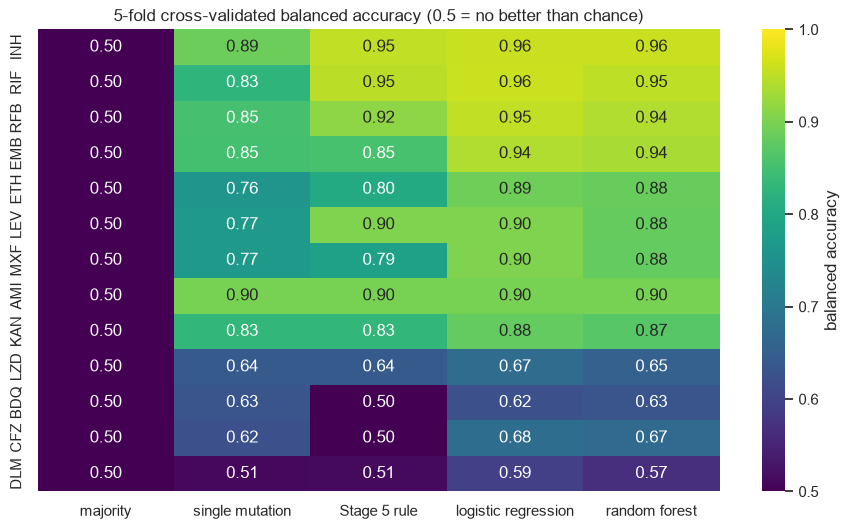

In [28]:
models = ["majority", "single mutation", "Stage 5 rule", "logistic regression", "random forest"]
bal = ml.pivot(index="drug", columns="model", values="balanced accuracy").reindex(index=DRUG_ORDER, columns=models)
fig, ax = plt.subplots(figsize=(11, 6))
sns.heatmap(bal, annot=True, fmt=".2f", cmap="viridis", vmin=0.5, vmax=1, ax=ax,
            cbar_kws={"label": "balanced accuracy"})
ax.set(title="5-fold cross-validated balanced accuracy (0.5 = no better than chance)", xlabel="", ylabel="")
plt.show()

wide = ml.set_index(["drug", "model"])[["sensitivity", "specificity", "AUC"]].unstack("model")
show = pd.concat({m_: wide.xs(m_, axis=1, level="model") for m_ in ["Stage 5 rule", "logistic regression", "random forest"]}, axis=1)
display(show.reindex(DRUG_ORDER).style.format("{:.2f}", na_rep="-"))

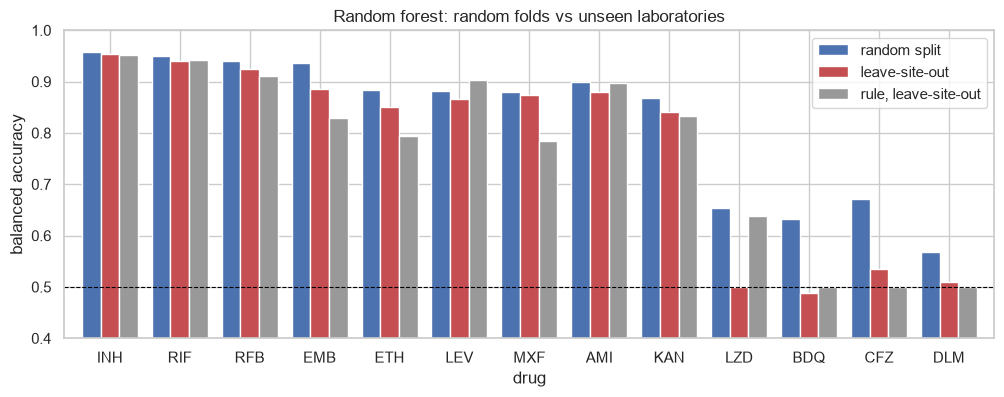

,random split,leave-site-out,"rule, leave-site-out"
drug,,,
INH,0.958,0.953,0.953
RIF,0.950,0.940,0.943
RFB,0.941,0.925,0.910
EMB,0.935,0.886,0.830
ETH,0.884,0.850,0.794
LEV,0.881,0.866,0.902
MXF,0.880,0.874,0.785
AMI,0.898,0.879,0.897
KAN,0.869,0.841,0.834


In [29]:
# Harder test: leave-laboratory-out (GroupKFold on SITEID)
gkf = GroupKFold(n_splits=5)
site_rows = []
for d in DRUG_ORDER:
    groups = iso.loc[y_all[d].index, "SITEID"].values
    r, _ = run_cv(d, gkf, groups, models=("Stage 5 rule", "logistic regression", "random forest"))
    site_rows += r
site = pd.DataFrame(site_rows)
compare = pd.DataFrame({
    "random split": ml[ml.model == "random forest"].set_index("drug")["balanced accuracy"],
    "leave-site-out": site[site.model == "random forest"].set_index("drug")["balanced accuracy"],
    "rule, leave-site-out": site[site.model == "Stage 5 rule"].set_index("drug")["balanced accuracy"],
}).reindex(DRUG_ORDER)
ax = compare.plot.bar(figsize=(12, 4), width=0.8, color=["#4c72b0", "#c44e52", "#999999"])
ax.set(ylim=(0.4, 1), ylabel="balanced accuracy", title="Random forest: random folds vs unseen laboratories")
ax.axhline(0.5, c="black", lw=0.8, ls="--")
plt.xticks(rotation=0)
plt.show()
display(compare.style.format("{:.3f}"))

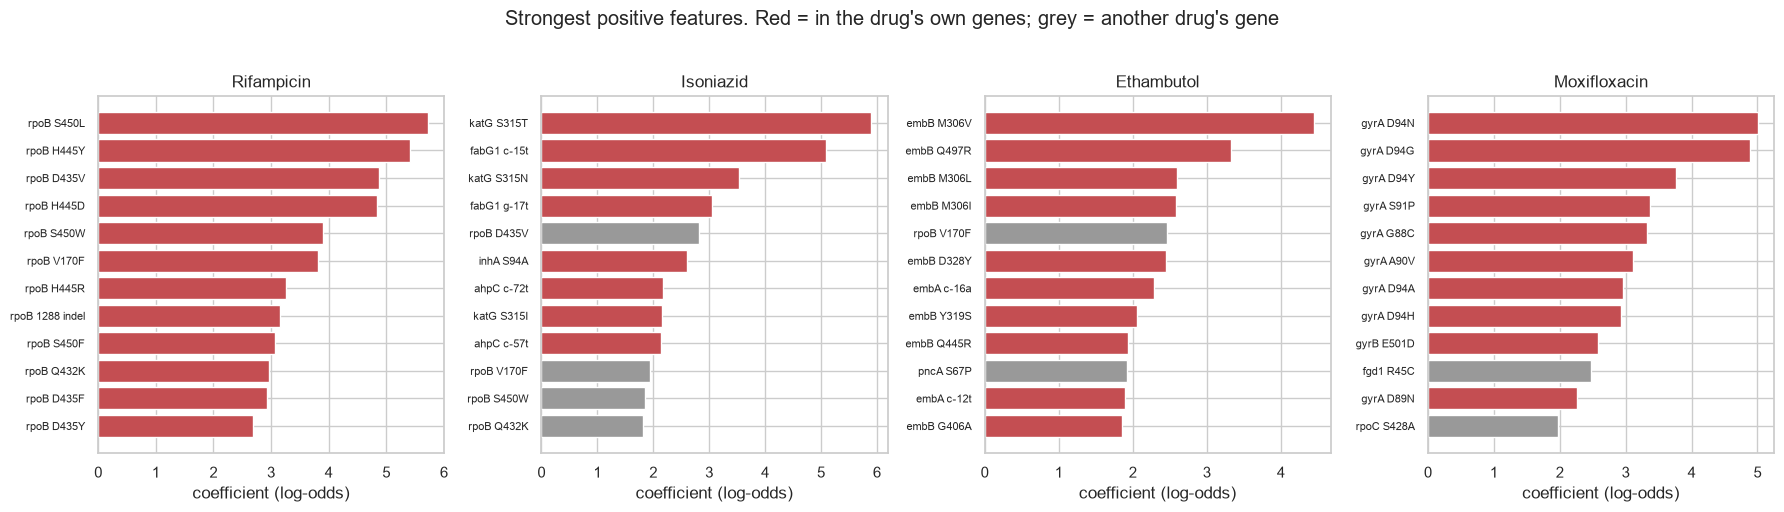

In [30]:
# What did the models learn? Top logistic-regression coefficients for four drugs, fitted on all data.
fig, axes = plt.subplots(1, 4, figsize=(18, 5))
for ax, d in zip(axes, ["RIF", "INH", "EMB", "MXF"]):
    y = y_all[d]
    lr = LogisticRegression(C=1.0, class_weight="balanced", max_iter=2000).fit(M.loc[y.index, feat], y)
    coef = pd.Series(lr.coef_[0], index=feat).sort_values(ascending=False).head(12)
    own = [mut_info.at[c, "GENE"] in DRUG_GENES[d] for c in coef.index]
    ax.barh([c.replace("_", " ") for c in coef.index][::-1], coef.values[::-1],
            color=["#c44e52" if o else "#999999" for o in own][::-1])
    ax.set(title=f"{DRUGS[d]}", xlabel="coefficient (log-odds)")
    ax.tick_params(axis="y", labelsize=8)
fig.suptitle("Strongest positive features. Red = in the drug's own genes; grey = another drug's gene", y=1.02)
plt.tight_layout()
plt.show()

**Interpretation (Stage 7).**

* **Every model beats the majority-class baseline** (balanced accuracy 0.50). For isoniazid and
  rifampicin, logistic regression and the random forest reach a balanced accuracy of 0.95–0.96,
  with sensitivity 93–94% and specificity 96–99%.
* **The simple Stage 5 rule is almost as good as ML for isoniazid, rifampicin, levofloxacin and
  amikacin.** For these drugs, "resistant if it carries any strongly linked mutation" captures
  nearly everything. ML adds the most for ethambutol (0.85 → 0.94), ethionamide (0.80 → 0.89)
  and moxifloxacin (0.79 → 0.90), where resistance is spread over many rarer mutations.
* **The single-mutation baseline exposes a shortcut.** For ethambutol, levofloxacin,
  moxifloxacin and bedaquiline, the best single mutation in the training data was *katG* S315T,
  an isoniazid mutation. It "predicts" these drugs only because it marks MDR strains. The
  coefficient plot shows the same effect inside the logistic regression: *rpoB* mutations appear
  among the top isoniazid features, and *rpoB* V170F among the ethambutol ones (grey bars). Part
  of the ML gain for these drugs is therefore co-resistance, not biology, and it would not hold
  in a population where the drug-resistance patterns differ.
* **Leave-laboratory-out testing.** For the common drugs, performance barely drops on
  laboratories the model never saw (e.g. isoniazid 0.958 → 0.953). For linezolid, bedaquiline,
  clofazimine and delamanid it falls to chance (0.49–0.54). Those models were learning
  site-specific patterns from very few resistant isolates. **We cannot predict resistance to the
  newer drugs from these data**, an honest negative result.

## Stage 8: Conclusions

**Answer to the research question.** In this collection of 11,972 clinical isolates, the
mutations most strongly linked to antibiotic resistance in *M. tuberculosis* are:

| Mutation | Drug(s) |
|---|---|
| *katG* S315T | isoniazid |
| *rpoB* S450L | rifampicin and rifabutin |
| the inhA-promoter mutation *fabG1* c-15t | isoniazid and ethionamide |
| *embB* M306V | ethambutol |
| *rrs* a1401g | amikacin and kanamycin |
| *gyrA* D94G and A90V | fluoroquinolones |
| *rpoB* D435V and H445Y | rifampicin |

Each has an odds ratio of roughly 50 to 500 and a positive predictive value of 0.88–0.99, and
sits in the drug's binding or activation site. The ones we tested stay linked within every
lineage, and when carried as the only mutation in the drug's genes.

**One point per objective**

1. **Dataset.** We linked 218,658 quality-filtered mutation calls in 43 genes to HIGH-quality
   laboratory results for 13 drugs in 11,972 isolates. About two-thirds of the raw calls were
   uncalled sites and were removed.
2. **Association.** 528 of 1,113 mutation–drug tests were significant at FDR < 0.05. 312 pairs
   met our "strongly linked" definition, but the solo analysis showed that some of these
   (*rpoC*, some *inhA* and *embC* mutations) are hitchhikers or compensatory mutations, not
   causes. Lineage adjustment removed the apparent links of lineage markers such as *katG* R463L.
3. **Biology.** The top mutations raise the MIC from about 5-fold (inhA promoter, isoniazid)
   to more than 100-fold (*rpoB*, *rrs*), cluster in known
   functional hotspots (RRDR, *katG* 315, *embB* 306, QRDR), and cause cross-resistance only
   between drugs that share a mechanism. The isoniazid/ethionamide pattern (*katG* versus
   inhA promoter) matches how the two drugs are activated. 22 of the top 26 per-drug mutations
   agree with the published literature.
4. **Machine learning.** Logistic regression and random forests predict resistance to the
   first- and second-line drugs with balanced accuracy 0.87–0.96, far above the majority-class
   baseline. They improve on a single mutation and, for ethambutol, ethionamide and
   moxifloxacin, on our Stage 5 rule. They fail on the newer drugs (bedaquiline, clofazimine,
   delamanid, linezolid), where they are no better than chance on unseen laboratories.

**The hypothesis** is supported for 9 of the 13 drugs. It is not supported for bedaquiline,
clofazimine, delamanid and linezolid, where no small set of mutations explains resistance.

**Limitations**

* **Not a prevalence sample.** CRyPTIC over-sampled resistant isolates and collected them through
  11 laboratories. Resistance rates and mutation frequencies here describe this collection, not
  Kenya or any other population.
* **Correlation, not proof.** Association, even within lineages and when solo, is strong evidence
  but not proof of cause; that needs allelic-exchange experiments in the laboratory.
* **Rare mutations are invisible.** Testing only mutations carried by 5 or more isolates misses
  them, and rare mutations dominate resistance to the newer drugs. Grouping loss-of-function
  mutations by gene would help.
* **Phenotype noise.** Using only HIGH-quality phenotypes reduced the sample by 20–45% per drug.
  Drugs whose MICs cluster near the ECOFF (ethambutol, fluoroquinolones) still have noisy R/S
  labels.
* **Only 43 candidate genes** were analysed, so resistance mechanisms elsewhere in the genome
  could not be found.
* **Co-resistance leaks into prediction.** MDR strains carry several resistances at once, so ML
  models partly learned shortcuts (e.g. using *katG* S315T to predict ethambutol resistance).

**Future steps**

* Group rare loss-of-function mutations (frameshifts, stop codons) by gene for bedaquiline,
  clofazimine and delamanid, and add newer collections with more resistant isolates.
* Run a genome-wide association study that corrects for population structure (e.g. a linear
  mixed model) to look beyond the 43 candidate genes.
* Validate the top mutations and the models on isolates from Kenya and other African settings.
* Map the top mutations onto the 3D structures of RNA polymerase, KatG and DNA gyrase to see how
  they change drug binding.